01 Exploratory Data Analysis (EDA)¶

In [1]:
# Pandas and numpy for data manipulation
%pip install pandas
%pip install matplotlib seaborn scipy
import pandas as pd
import numpy as np
np.random.seed(123)
# Matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
matplotlib.rcParams['font.size'] = 8
matplotlib.rcParams['figure.figsize'] = (5, 5)
import seaborn as sns
from IPython.core.pylabtools import figsize
# Scipy helper functions
import scipy
from scipy.stats import percentileofscore
from scipy import stats

#time series
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from statsmodels.graphics.tsaplots import plot_acf

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Part 1. Check data set, explore/add columns.

In [2]:
import pandas as pd

# Source: Civil Aviation Authority of Singapore, via data.gov.sg
# Each row represents one month at Singapore Changi Airport.
df = pd.read_csv("AirTrafficMovements.csv", thousands=",")

print("Rows and columns:", df.shape)

Rows and columns: (139, 15)


In [3]:
#url = "https://raw.githubusercontent.com/angh0059/KM6312group8/refs/heads/main/AirTrafficMovements.csv?token=GHSAT0AAAAAAELWDTWQBIKGNQMHOGK4JCH42W6AQ4A"
#df = pd.read_csv(url)
df.head()

,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,AirMail_Outgoing,AirMail_Total,Cargo_Total_Import,Cargo_Total_Export,Cargo_Total
0,2015,2015-01,14384,14396,28780,2243305,2112813,64004,4420122,1193.6200,1614.88,2808.50,81867.90,69946.38,151814.28
1,2015,2015-02,13249,13242,26491,2018729,2056989,45639,4121357,974.9702,1277.43,2252.40,75576.73,60388.68,135965.42
2,2015,2015-03,14390,14403,28793,2237167,2245963,51989,4535119,1112.6200,1485.10,2597.72,89020.39,73639.48,162659.86
3,2015,2015-04,14126,14130,28256,2181441,2151585,58355,4391381,1095.8200,1391.80,2487.62,83906.47,69541.16,153447.64
4,2015,2015-05,14519,14523,29042,2177764,2250744,51753,4480261,1183.5100,1523.83,2707.34,86950.64,70095.57,157046.21


In [4]:
# check the size of the dataset
print ("Dataset size:", df.shape)

Dataset size: (139, 15)


In [5]:
# Check the data structure (use .info())
print ("Data structure - Airport :")
df.info()

Data structure - Airport :
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  139 non-null    int64  
 1   Month                 139 non-null    str    
 2   Aircraft_Arrival      139 non-null    int64  
 3   Aircraft_Departure    139 non-null    int64  
 4   Aircraft_Total        139 non-null    int64  
 5   Passenger_Arrival     139 non-null    int64  
 6   Passenger_Departures  139 non-null    int64  
 7   Passenger_Transit     139 non-null    int64  
 8   Passenger_Total       139 non-null    int64  
 9   AirMail_Incoming      139 non-null    float64
 10  AirMail_Outgoing      139 non-null    float64
 11  AirMail_Total         139 non-null    float64
 12  Cargo_Total_Import    139 non-null    float64
 13  Cargo_Total_Export    139 non-null    float64
 14  Cargo_Total           139 non-null    float64
dtypes: floa

In [6]:
# Convert the month to a date and sort the rows from oldest to newest.
df["Month"] = pd.to_datetime(df["Month"], format="%Y-%m")
df = df.sort_values("Month").reset_index(drop=True)

# Keep the month number for the team's charts.
df["month_dummy"] = df["Month"].dt.month

# Check the first and last months.
print(df[["Month", "month_dummy"]].iloc[[0, -1]])

         Month  month_dummy
0   2015-01-01            1
138 2026-07-01            7


In [7]:
#convert columns to float
# 1. Count empty values in each column.
print(df.isna().sum())

# 2. Count repeated months.
duplicate_months = df["Month"].duplicated().sum()
print("Duplicate months:", duplicate_months)

# 3. Check whether any month is missing from the study period.
expected_months = pd.date_range("2015-01-01", "2026-07-01", freq="MS")
missing_months = expected_months.difference(df["Month"])
print("Number of missing months:", len(missing_months))

Year                    0
Month                   0
Aircraft_Arrival        0
Aircraft_Departure      0
Aircraft_Total          0
Passenger_Arrival       0
Passenger_Departures    0
Passenger_Transit       0
Passenger_Total         0
AirMail_Incoming        0
AirMail_Outgoing        0
AirMail_Total           0
Cargo_Total_Import      0
Cargo_Total_Export      0
Cargo_Total             0
month_dummy             0
dtype: int64
Duplicate months: 0
Number of missing months: 0


In [8]:
passenger_sum = df["Passenger_Arrival"] + df["Passenger_Departures"] + df["Passenger_Transit"]
passenger_mismatch = df["Passenger_Total"] != passenger_sum
print("Months with a passenger total mismatch:", passenger_mismatch.sum())

Months with a passenger total mismatch: 0


In [9]:
# Aircraft: count the months where arrivals + departures differ from the total.
aircraft_sum = df["Aircraft_Arrival"] + df["Aircraft_Departure"]
aircraft_mismatch = df["Aircraft_Total"] != aircraft_sum
print("Months with an aircraft total mismatch:", aircraft_mismatch.sum())

# Air mail: find the largest difference.
mail_sum = df["AirMail_Incoming"] + df["AirMail_Outgoing"]
mail_difference = df["AirMail_Total"] - mail_sum
print("Largest air mail difference:", round(mail_difference.abs().max(), 4))

# Cargo: find the largest difference.
cargo_sum = df["Cargo_Total_Import"] + df["Cargo_Total_Export"]
cargo_difference = df["Cargo_Total"] - cargo_sum
print("Largest cargo difference:", round(cargo_difference.abs().max(), 4))

Months with an aircraft total mismatch: 0
Largest air mail difference: 0.01
Largest cargo difference: 1.0


In [10]:
#use cosine to show month continuity

# Encode cyclically
df['month_sin'] = np.sin(2 * np.pi * df['month_dummy'] / 12.0)
df['month_cos'] = np.cos(2 * np.pi * df['month_dummy'] / 12.0)

# Track external structural events (COVID timeline indicator)
df['iscovid'] = np.where((df['Year'] >= 2020) & (df['Year'] <= 2022), 1, 0)
df["IsHoliday"] = df["month_dummy"].isin([6, 12]).astype(int)
print("Months marked as school holidays:", df["IsHoliday"].sum())
df.head()

Months marked as school holidays: 23


,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,AirMail_Outgoing,AirMail_Total,Cargo_Total_Import,Cargo_Total_Export,Cargo_Total,month_dummy,month_sin,month_cos,iscovid,IsHoliday
0,2015,2015-01-01,14384,14396,28780,2243305,2112813,64004,4420122,1193.6200,1614.88,2808.50,81867.90,69946.38,151814.28,1,0.500000,8.660254e-01,0,0
1,2015,2015-02-01,13249,13242,26491,2018729,2056989,45639,4121357,974.9702,1277.43,2252.40,75576.73,60388.68,135965.42,2,0.866025,5.000000e-01,0,0
2,2015,2015-03-01,14390,14403,28793,2237167,2245963,51989,4535119,1112.6200,1485.10,2597.72,89020.39,73639.48,162659.86,3,1.000000,6.123234e-17,0,0
3,2015,2015-04-01,14126,14130,28256,2181441,2151585,58355,4391381,1095.8200,1391.80,2487.62,83906.47,69541.16,153447.64,4,0.866025,-5.000000e-01,0,0
4,2015,2015-05-01,14519,14523,29042,2177764,2250744,51753,4480261,1183.5100,1523.83,2707.34,86950.64,70095.57,157046.21,5,0.500000,-8.660254e-01,0,0


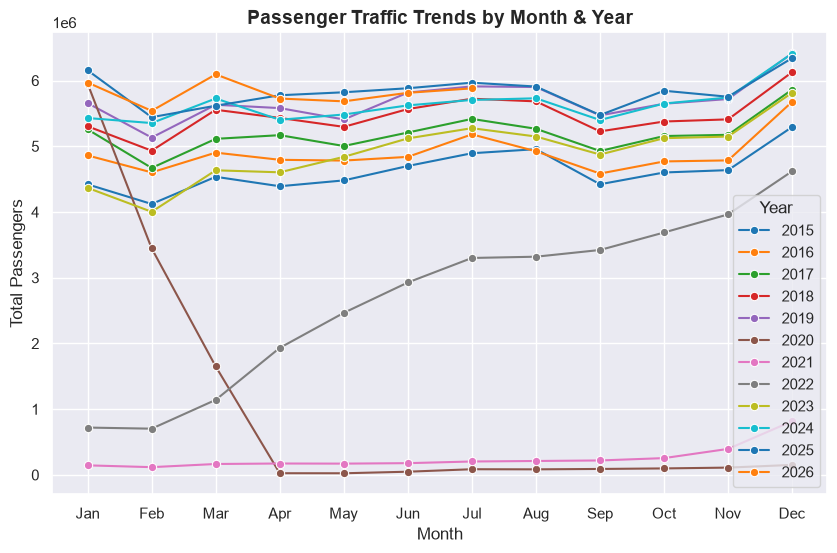

In [11]:
#Visualisation
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")

# Line plot dividing traffic trends by year
sns.lineplot(
    data=df, 
    x='month_dummy', 
    y='Passenger_Total', 
    hue='Year',        # Separate line for each year
    marker='o',        # Add dots to monthly points
    palette='tab10'
)

plt.title('Passenger Traffic Trends by Month & Year', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Passengers')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

In [12]:
#present totals per day so that months with lesser days don't appear as dips
days_in_month = pd.to_datetime(df['Month']).dt.days_in_month

cols = ['Aircraft_Total', 'Passenger_Total', 'AirMail_Total', 'Cargo_Total', 'Passenger_Transit']

for col in cols:
    df[f'{col}_Per_Day'] = df[col] / days_in_month

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Year                       139 non-null    int64         
 1   Month                      139 non-null    datetime64[us]
 2   Aircraft_Arrival           139 non-null    int64         
 3   Aircraft_Departure         139 non-null    int64         
 4   Aircraft_Total             139 non-null    int64         
 5   Passenger_Arrival          139 non-null    int64         
 6   Passenger_Departures       139 non-null    int64         
 7   Passenger_Transit          139 non-null    int64         
 8   Passenger_Total            139 non-null    int64         
 9   AirMail_Incoming           139 non-null    float64       
 10  AirMail_Outgoing           139 non-null    float64       
 11  AirMail_Total              139 non-null    float64       
 12  Cargo_Total_Import 

,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,...,month_dummy,month_sin,month_cos,iscovid,IsHoliday,Aircraft_Total_Per_Day,Passenger_Total_Per_Day,AirMail_Total_Per_Day,Cargo_Total_Per_Day,Passenger_Transit_Per_Day
0,2015,2015-01-01,14384,14396,28780,2243305,2112813,64004,4420122,1193.6200,...,1,0.500000,8.660254e-01,0,0,928.387097,142584.580645,90.596774,4897.234839,2064.645161
1,2015,2015-02-01,13249,13242,26491,2018729,2056989,45639,4121357,974.9702,...,2,0.866025,5.000000e-01,0,0,946.107143,147191.321429,80.442857,4855.907857,1629.964286
2,2015,2015-03-01,14390,14403,28793,2237167,2245963,51989,4535119,1112.6200,...,3,1.000000,6.123234e-17,0,0,928.806452,146294.161290,83.797419,5247.092258,1677.064516
3,2015,2015-04-01,14126,14130,28256,2181441,2151585,58355,4391381,1095.8200,...,4,0.866025,-5.000000e-01,0,0,941.866667,146379.366667,82.920667,5114.921333,1945.166667
4,2015,2015-05-01,14519,14523,29042,2177764,2250744,51753,4480261,1183.5100,...,5,0.500000,-8.660254e-01,0,0,936.838710,144524.548387,87.333548,5066.006774,1669.451613


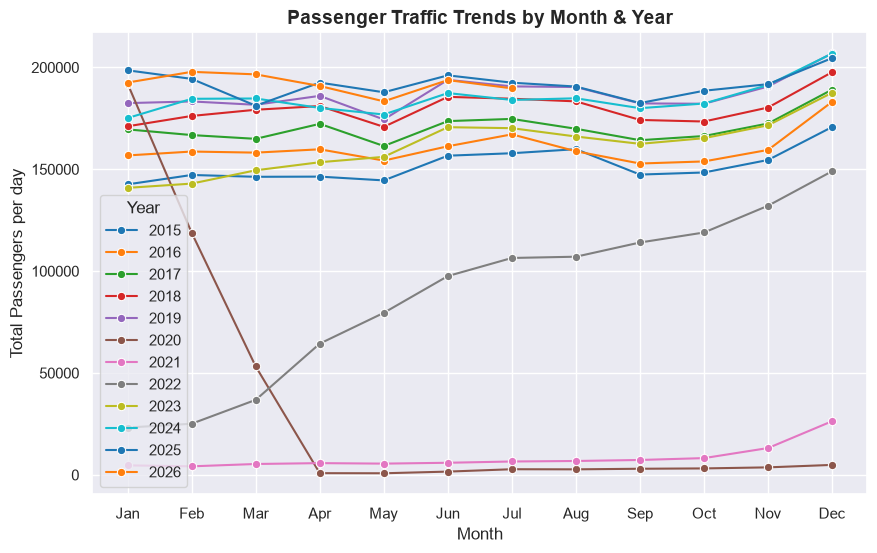

In [13]:
#Visualisation by day
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")

# Line plot dividing traffic trends by year
sns.lineplot(
    data=df, 
    x='month_dummy', 
    y='Passenger_Total_Per_Day', 
    hue='Year',        # Separate line for each year
    marker='o',        # Add dots to monthly points
    palette='tab10'
)

plt.title('Passenger Traffic Trends by Month & Year', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Passengers per day')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

In [14]:
df.describe()

,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,...,month_dummy,month_sin,month_cos,iscovid,IsHoliday,Aircraft_Total_Per_Day,Passenger_Total_Per_Day,AirMail_Total_Per_Day,Cargo_Total_Per_Day,Passenger_Transit_Per_Day
count,139.000000,139,139.000000,139.000000,139.000000,1.390000e+02,1.390000e+02,139.000000,1.390000e+02,139.000000,...,139.000000,1.390000e+02,1.390000e+02,139.000000,139.000000,139.000000,139.000000,139.000000,139.000000,139.000000
mean,2020.302158,2020-09-30 14:40:34.532374,12907.172662,12911.640288,25818.812950,2.133475e+06,2.102910e+06,41164.625899,4.277550e+06,828.832140,...,6.374101,2.325216e-02,-1.342464e-02,0.258993,0.165468,848.467876,140544.393510,73.955113,5330.485008,1351.401164
min,2015.000000,2015-01-01 00:00:00,1920.000000,1945.000000,3865.000000,3.976000e+03,1.734000e+04,17.000000,2.450400e+04,226.584900,...,1.000000,-1.000000e+00,-1.000000e+00,0.000000,0.000000,128.833333,790.451613,24.069452,3194.588333,0.548387
25%,2017.000000,2017-11-16 00:00:00,12634.500000,12629.500000,25264.000000,2.008518e+06,2.030003e+06,37982.500000,4.062046e+06,518.856200,...,3.000000,-5.000000e-01,-8.660254e-01,0.000000,0.000000,817.046083,141726.354839,44.498177,4978.570715,1258.080645
50%,2020.000000,2020-10-01 00:00:00,14962.000000,14968.000000,29930.000000,2.549697e+06,2.522088e+06,46238.000000,5.131807e+06,706.633600,...,6.000000,1.224647e-16,-1.836970e-16,0.000000,0.000000,983.379310,167132.516129,70.421935,5365.304000,1531.500000
75%,2023.000000,2023-08-16 12:00:00,15697.500000,15695.500000,31393.000000,2.796524e+06,2.762344e+06,54570.000000,5.638712e+06,1119.625000,...,9.000000,8.660254e-01,5.000000e-01,1.000000,0.000000,1030.901613,183666.887097,101.754447,5734.769500,1760.322581
max,2026.000000,2026-07-01 00:00:00,16719.000000,16716.000000,33435.000000,3.231750e+06,3.144724e+06,81042.000000,6.414495e+06,1568.850000,...,12.000000,1.000000e+00,1.000000e+00,1.000000,1.000000,1079.392857,206919.193548,169.517742,6389.221000,2614.258065
std,3.361450,NaN,4413.203002,4411.578744,8824.772208,1.000948e+06,9.802374e+05,20474.589147,1.998637e+06,340.162276,...,3.450002,7.080021e-01,7.108117e-01,0.439666,0.372946,289.102342,65492.480003,33.530146,589.227562,667.978285


Part 2: Data visualisations to look for patterns

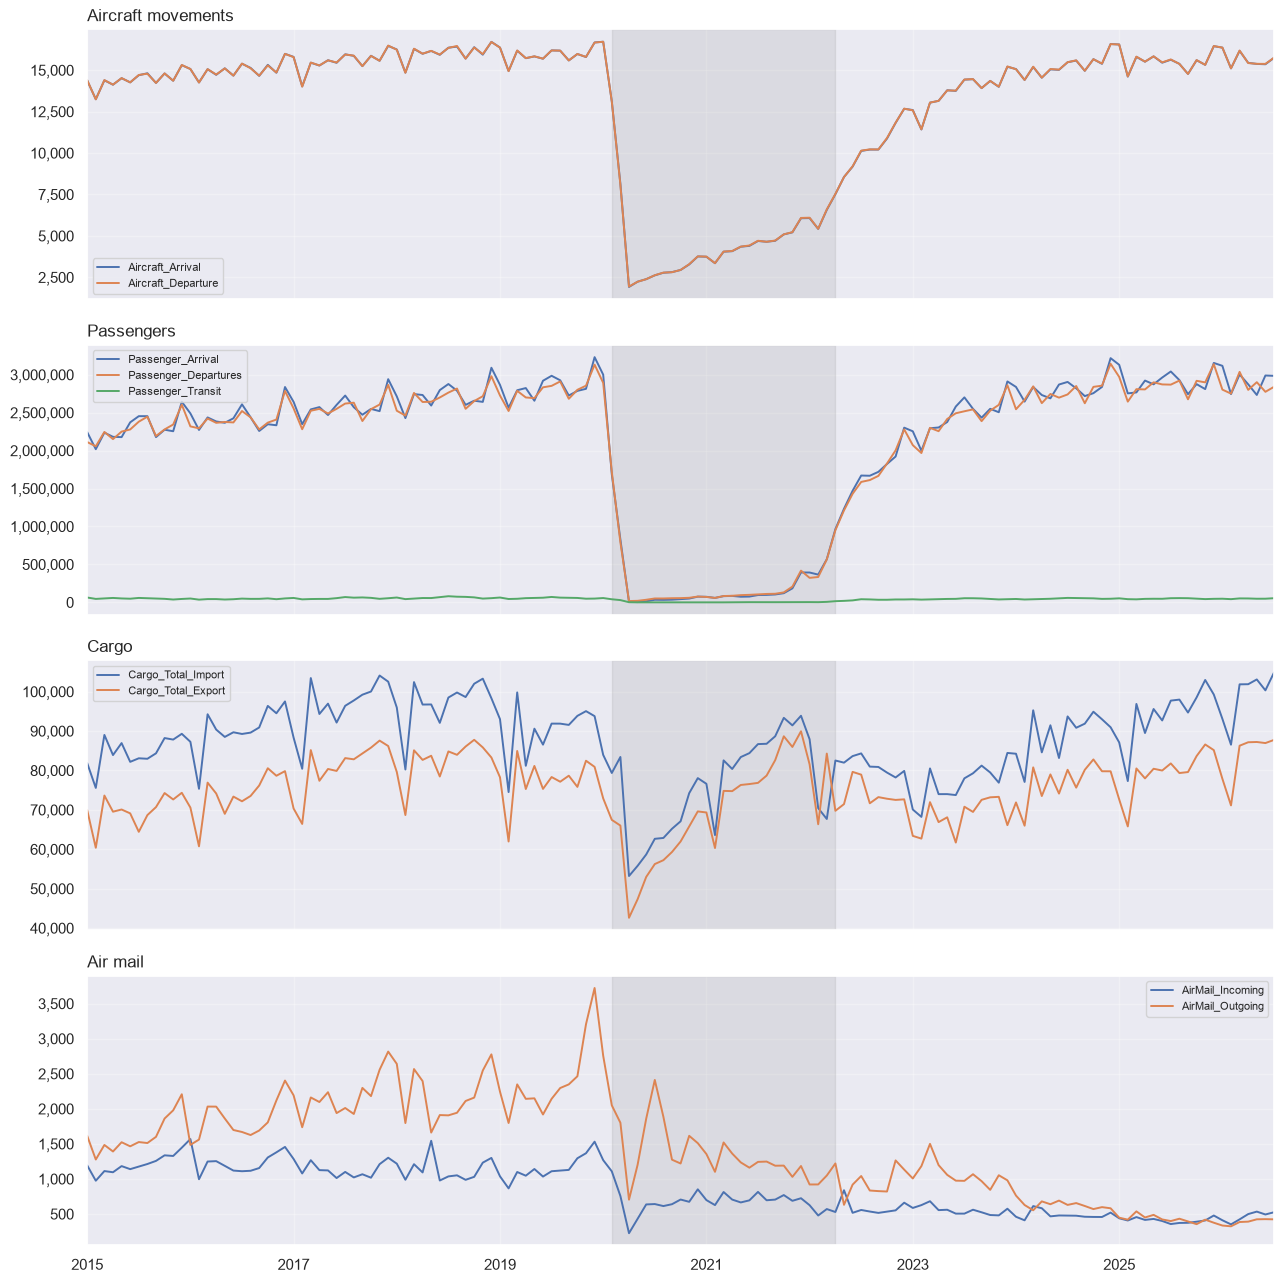

In [15]:
#Line charts by group (inbound vs outbound)
COVID = (pd.Timestamp("2020-02-01"), pd.Timestamp("2022-04-01"))
d = df.set_index("Month").sort_index()
    
groups = {
    "Aircraft movements": ["Aircraft_Arrival", "Aircraft_Departure"],
    "Passengers":         ["Passenger_Arrival", "Passenger_Departures", "Passenger_Transit"],
    "Cargo":              ["Cargo_Total_Import", "Cargo_Total_Export"],
    "Air mail":           ["AirMail_Incoming", "AirMail_Outgoing"],
}
fig, axes = plt.subplots(len(groups), 1, figsize=(13, 13), sharex=True)
for ax, (title, cols) in zip(axes, groups.items()):
    d[cols].plot(ax=ax, lw=1.4)
    ax.axvspan(*COVID, color="grey", alpha=0.15)
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[-1].set_xlabel("")
fig.tight_layout()
plt.show()

Figure X. Monthly inbound and outbound traffic by category, January 2015 – July 2026 (shaded: COVID-19 disruption, February 2020 – April 2022)

Aircraft arrivals and departures are almost identical in every month, since each aircraft that lands also departs. Movements grew from about 14,400 a month in each direction in 2015 to about 16,700 in late 2019. They fell by nearly 90% in April 2020 and returned to about 15,500–16,500 by 2024–2025. Passenger arrivals and departures also closely match each other. They rose from about 2.2 million to 3.2 million a month in each direction by December 2019, fell almost to zero from April 2020 to late 2021, and recovered to about 3 million by 2024–2025. Transit passengers (about 50,000 a month) are a negligible share of the total.
Cargo imports consistently exceeded exports, by about 10,000–20,000 a month. Cargo was the most resilient category: it fell to about half its normal level in April 2020, regained pre-pandemic levels by late 2021, and reached a series high of about 105,000 imports in July 2026.
Air mail followed a different pattern. Before the pandemic, outgoing mail was roughly twice incoming mail, with clear year-end peaks (up to about 3,700 in December 2019). Both directions fell sharply in early 2020 and, unlike passengers and cargo, did not return to pre-pandemic levels. Outgoing mail declined steadily after 2021, and by 2025 it had fallen to about the same level as incoming mail (around 400–500 a month). Since late 2025, incoming mail has slightly exceeded outgoing, reversing the pre-pandemic pattern. This points to a sustained decline in air mail, likely linked to the shift from physical post to digital communication, rather than a temporary effect of the pandemic.

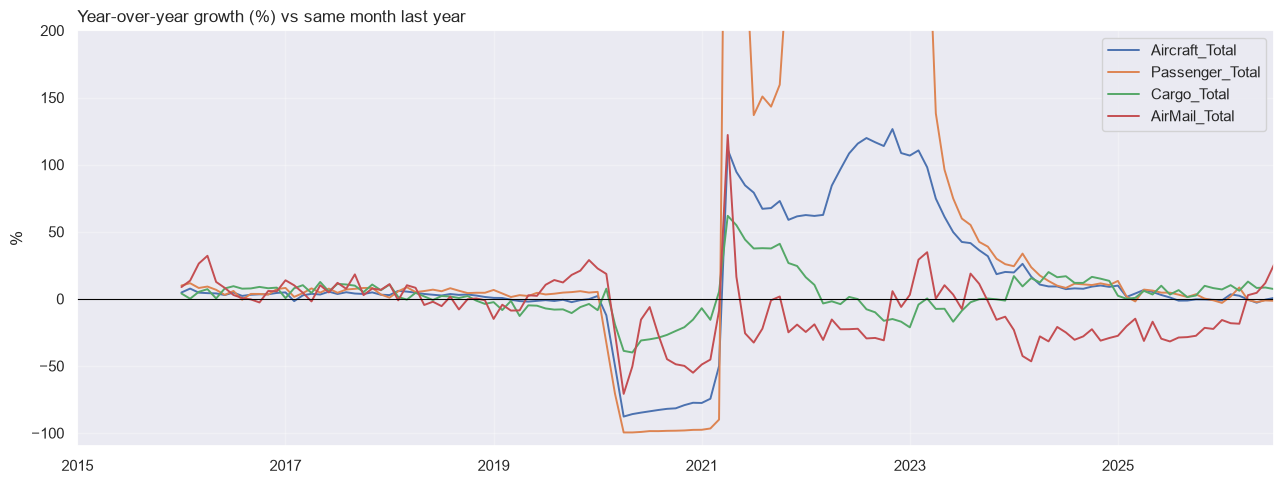

In [16]:
#Year-over-year growth
totals = ["Aircraft_Total", "Passenger_Total", "Cargo_Total", "AirMail_Total"]
yoy = d[totals].pct_change(12, fill_method=None) * 100

fig, ax = plt.subplots(figsize=(13, 5))
yoy.plot(ax=ax, lw=1.4)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-110, 200)        # 2021-22 rebound reaches +1000s %; clipped so normal years stay readable
ax.set_title("Year-over-year growth (%) vs same month last year", loc="left")
ax.set_ylabel("%"); ax.set_xlabel("")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Figure Y. Year-over-year growth (%) vs. the same month of the previous year, 2016–2026

Before COVID-19, aircraft movements, passengers and cargo grew steadily at about 0–10% a year, while air mail fluctuated more widely. In 2020, passengers fell by almost 100% and aircraft by about 87%, but cargo fell only about 40% and recovered fastest. The very high growth rates in 2021–2023 are a base effect from comparing against the depressed pandemic months, not genuine expansion. From 2024, aircraft, passengers and cargo returned to normal growth of 0–15%. Air mail, by contrast, declined by 15–32% year-on-year in every month from 2024 to March 2026. It turned positive from April 2026, driven by higher incoming mail, but this is too recent to indicate a sustained recovery, and volumes remain about a quarter of 2019 levels.


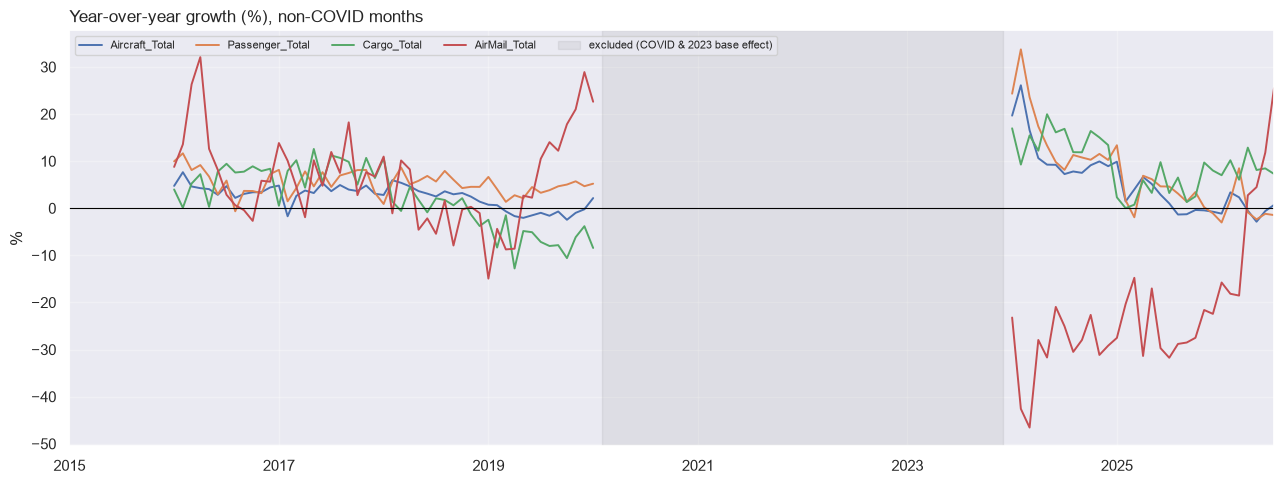

In [17]:
# Year-over-year growth, non-COVID months only
totals = ["Aircraft_Total", "Passenger_Total", "Cargo_Total", "AirMail_Total"]
yoy = d[totals].pct_change(12, fill_method=None) * 100

normal = (yoy.index <= "2020-01-31") | (yoy.index >= "2024-01-01")
yoy_normal = yoy.copy()
yoy_normal.loc[~normal] = np.nan

fig, ax = plt.subplots(figsize=(13, 5))
yoy_normal.plot(ax=ax, lw=1.4)
ax.axhline(0, color="black", lw=0.8)
ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2023-12-31"),
           color="grey", alpha=0.12, label="excluded (COVID & 2023 base effect)")
ax.set_title("Year-over-year growth (%), non-COVID months", loc="left")
ax.set_ylabel("%"); ax.set_xlabel("")
ax.legend(fontsize=8, ncol=5)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Part 4: Clustering pre-checks
Pair plots: Check before clustering: whether groups are already visible and which features are redundant.

Period
Pre-COVID (2015-Jan 2020)    61
Post-COVID (2023-)           43
COVID (Feb 2020-Mar 2022)    26
Recovery (Apr-Dec 2022)       9
Name: count, dtype: int64


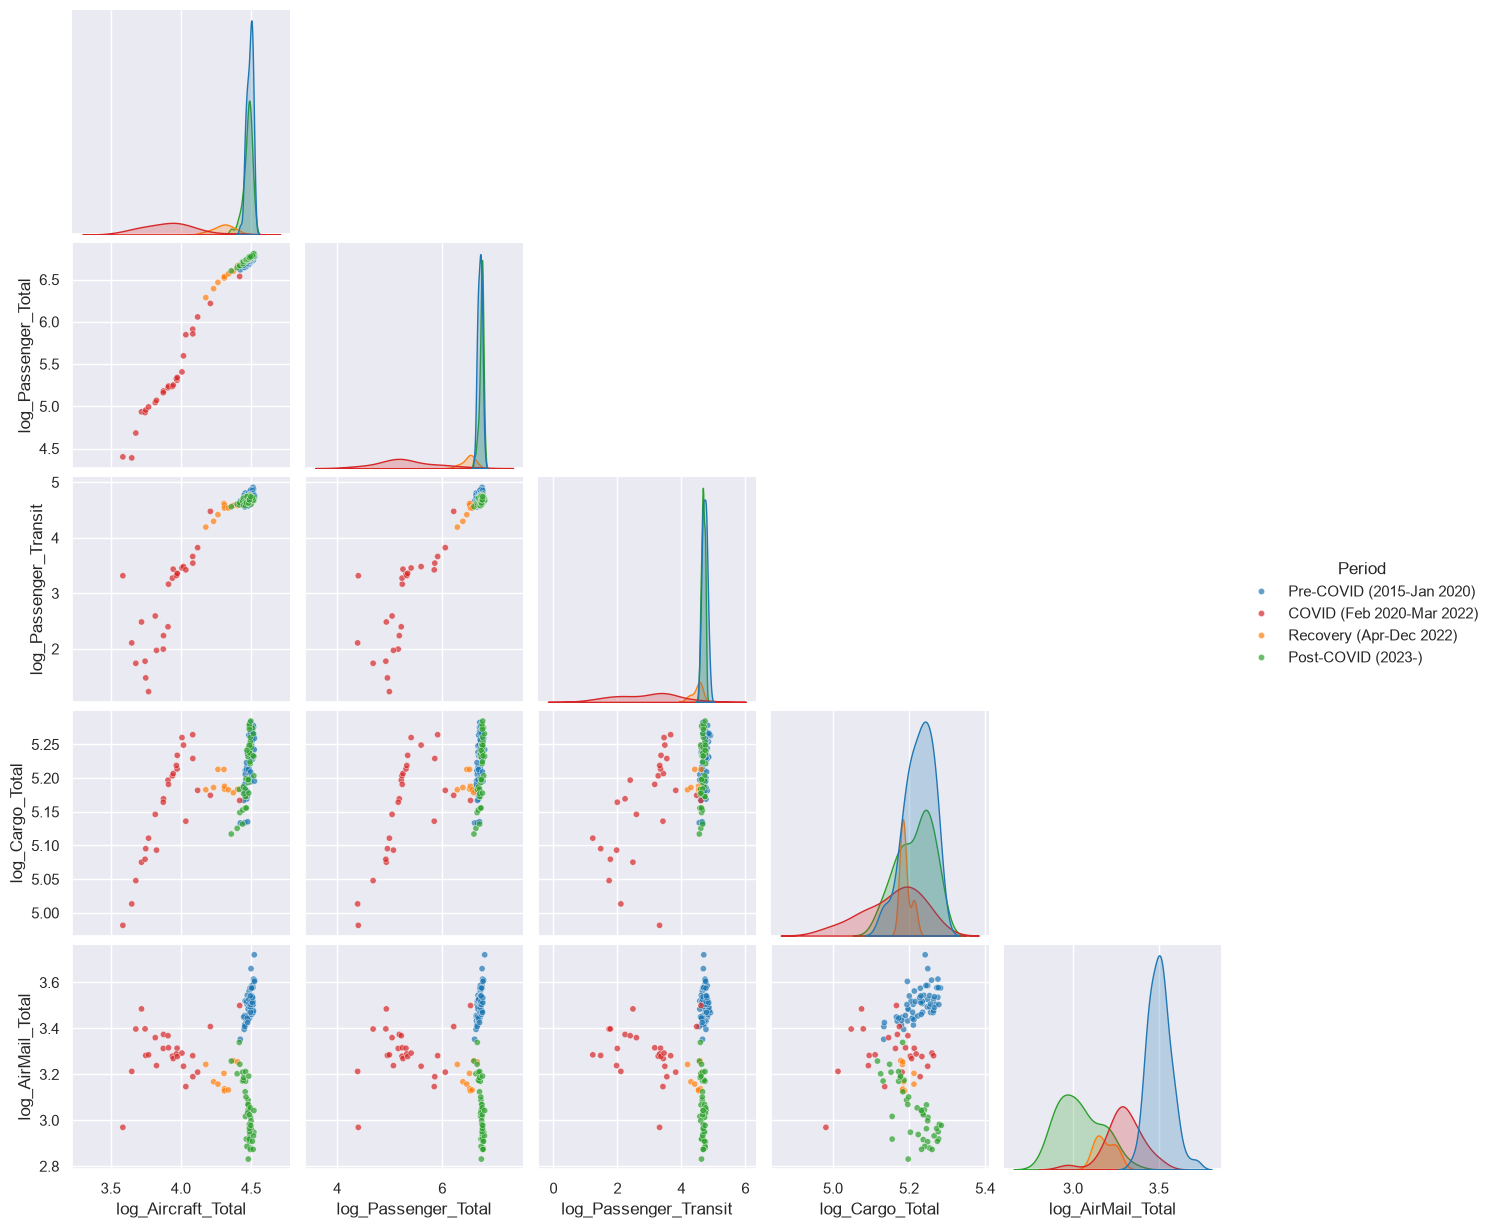

In [18]:
#pair plots
def period(t):
    if t < pd.Timestamp("2020-02-01"): return "Pre-COVID (2015-Jan 2020)"
    if t < pd.Timestamp("2022-04-01"): return "COVID (Feb 2020-Mar 2022)"
    if t < pd.Timestamp("2023-01-01"): return "Recovery (Apr-Dec 2022)"
    return "Post-COVID (2023-)"

colors = {"Pre-COVID (2015-Jan 2020)": "tab:blue",
          "COVID (Feb 2020-Mar 2022)": "tab:red",
          "Recovery (Apr-Dec 2022)":   "tab:orange",
          "Post-COVID (2023-)":        "tab:green"}

# Build d with a date index and a Period column
d = df.copy()
if "Month" in d.columns:
    d["Month"] = pd.to_datetime(d["Month"])
    d = d.set_index("Month").sort_index()
else:
    d.index = pd.to_datetime(d.index)
d["Period"] = d.index.map(period)
print(d["Period"].value_counts())

# Pairplot of log totals
cols = ["Aircraft_Total", "Passenger_Total", "Passenger_Transit", "Cargo_Total", "AirMail_Total"]
logd = np.log10(d[cols]).add_prefix("log_")
logd["Period"] = d["Period"]

sns.pairplot(logd, hue="Period", palette=colors, corner=True,
             diag_kind="kde", plot_kws=dict(s=20, alpha=0.7))
plt.show()

This pairplot shows every pair of your five main indicators against each other, on log scales, with each month coloured by period. Here’s how to read it and what it shows.

How to read it
Off-diagonal panels (the scatterplots). Each dot is one month. Its position compares two indicators, for example aircraft movements on the x-axis and passengers on the y-axis. These panels show how two indicators relate.
Diagonal panels (the curves). Each curve shows how one indicator’s values are distributed within a period. A tall, narrow peak means the values were stable. A wide, flat curve means they varied a lot.
The axes are log10. Each step of 1 means ×10. As a guide: aircraft 4.5 ≈ 32,000 flights, passengers 6.7 ≈ 5 million, transit 4.7 ≈ 50,000, cargo 5.2 ≈ 160,000, air mail 3.5 ≈ 3,200.
What it shows

1. Passengers and flights move together, but passengers fell further (the aircraft vs. passengers panel).
All periods lie along one tight line: more flights mean more passengers. The COVID months (red) run down to the bottom left. The line is steep: flights fell by about 0.9 on the log scale (to about one-eighth), but passengers fell by about 2.3 (to about 1/200th). So the remaining flights were nearly empty. Pre-COVID (blue) and post-COVID (green) months sit in the same spot, showing that passenger traffic fully recovered.

2. Cargo held up during COVID (the aircraft vs. cargo panel).
This is the most telling panel. In normal times (blue and green), the dots form a vertical strip: flights stay at about the same level while cargo varies, so cargo isn’t driven by the number of flights. During COVID (red), the dots rise diagonally, but they reach normal cargo levels (5.2–5.25) with only about one-third of the usual flights. The airport kept moving freight with far fewer aircraft, using cargo-only and converted passenger flights. On the cargo diagonal panel, all four periods overlap, so cargo was barely affected overall.

3. Air mail declined for good (the bottom row and the air mail diagonal).
Air mail is the only indicator with three separate peaks: pre-COVID highest (about 3.5, ≈3,200), COVID in the middle (about 3.3) and post-COVID lowest (about 3.0, ≈1,000). The post-COVID level is even lower than during COVID. In the aircraft vs. air mail panel, the blue and green dots share the same flight levels but sit at very different mail levels. So the decline has nothing to do with how many flights there are; it’s a long-term drop in mail.

4. Transit is the noisiest series (the transit row).
It follows the same line as passengers, but the COVID points scatter widely at the bottom. Transit fell to between 17 and a few hundred passengers a month, and small numbers like these jump around a lot.

5. The recovery months sit in between.
The orange points (Apr–Dec 2022) lie between the COVID and normal groups in every panel. That fits a transition period.

What it means for clustering
The aircraft, passenger and transit panels are redundant. They lie along nearly the same line, so they carry the same information. Use one of them, or a ratio like passengers per flight.
Cargo and air mail separate the periods best. The cargo vs. air mail panel splits pre-COVID (top right) from post-COVID (bottom) even though their passenger levels are identical. That’s information the passenger data alone can’t give.
The periods separate clearly, which is visual support for the K-Means result: COVID forms a distinct regime, while the pre- and post-COVID months differ mainly in air mail.

A one-line summary for your report: “Passenger traffic fell about 99% and fully recovered, cargo was largely unaffected, and air mail has declined for good regardless of flight volumes.”

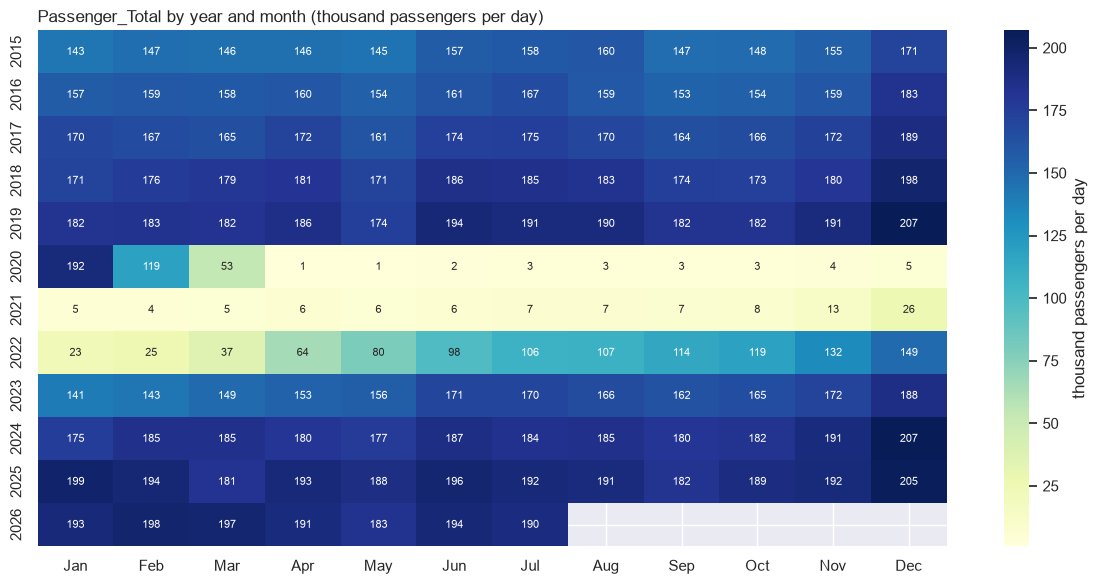

In [19]:
#Year × month heatmap for passenger per day
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

col = "Passenger_Total_Per_Day"      # or "Aircraft_Total_Per_Day", "Cargo_Total_Per_Day"

# divisor, number format, unit label for per-day values
units = {
    "Passenger_Total_Per_Day": (1e3, ".0f",  "thousand passengers per day"),
    "Aircraft_Total_Per_Day":  (1,   ",.0f", "aircraft movements per day"),
    "Cargo_Total_Per_Day":     (1,   ",.0f", "cargo per day"),
}
div, fmt, label = units[col]

hm = d[[col]].copy()
hm["per_day"] = hm[col]                     # already per day, so no second division
hm["Year"], hm["Mon"] = hm.index.year, hm.index.strftime("%b")
table = hm.pivot(index="Year", columns="Mon", values="per_day")[MONTHS]

plt.figure(figsize=(12, 6))
sns.heatmap(table / div, annot=True, fmt=fmt, cmap="YlGnBu",
            annot_kws={"size": 8}, cbar_kws={"label": label})
plt.title(f"{col.replace('_Per_Day', '')} by year and month ({label})", loc="left")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout()
plt.show()

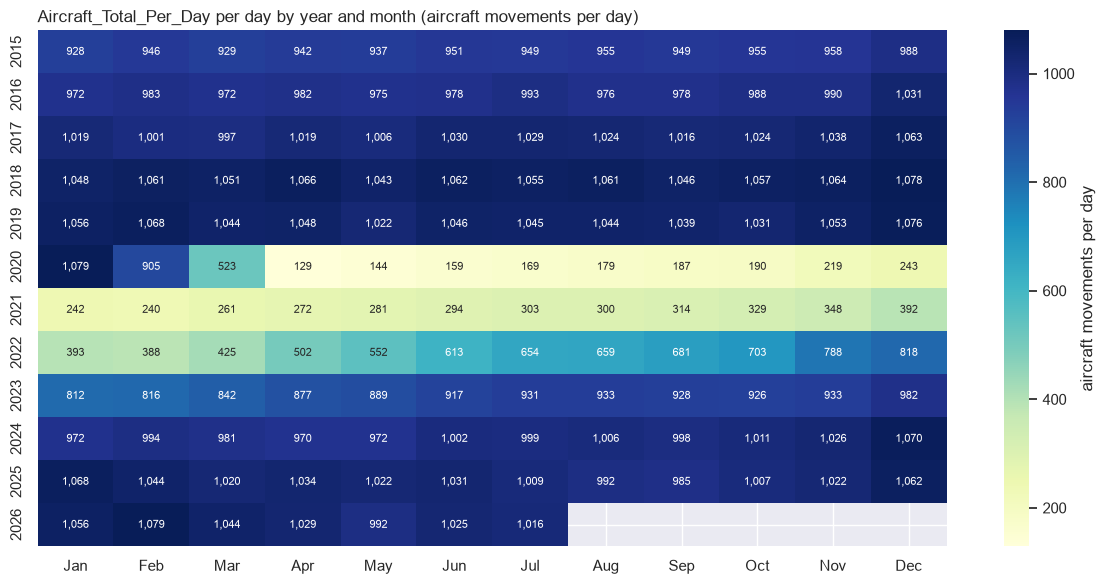

In [20]:
#Year × month heatmap for cargo

col = "Aircraft_Total_Per_Day"      

# divisor, number format, unit label for per-day values
units = {
    "Passenger_Total_Per_Day": (1e3, ".0f",  "thousand passengers per day"),
    "Aircraft_Total_Per_Day":  (1,   ",.0f", "aircraft movements per day"),
    "Cargo_Total_Per_Day":     (1,   ",.0f", "cargo per day"),
}
div, fmt, label = units[col]

hm = d[[col]].copy()
hm["per_day"] = hm[col] 
hm["Year"], hm["Mon"] = hm.index.year, hm.index.strftime("%b")
table = hm.pivot(index="Year", columns="Mon", values="per_day")[MONTHS]

plt.figure(figsize=(12, 6))
sns.heatmap(table / div, annot=True, fmt=fmt, cmap="YlGnBu",
            annot_kws={"size": 8}, cbar_kws={"label": label})
plt.title(f"{col} per day by year and month ({label})", loc="left")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout()
plt.show()

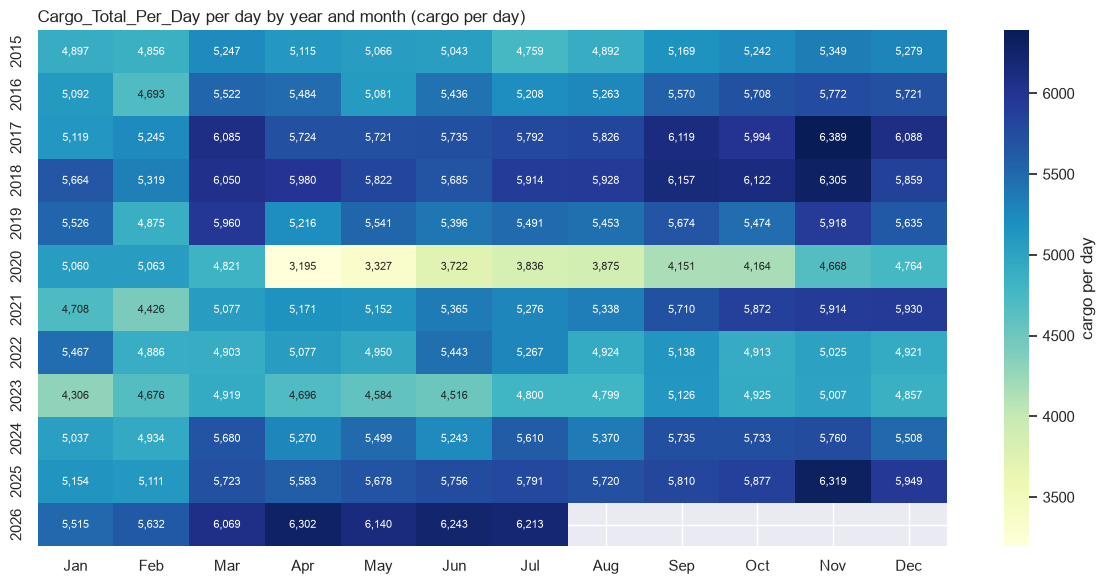

In [21]:
#Year × month heatmap for aircraft

col = "Cargo_Total_Per_Day"    

# divisor, number format, unit label for per-day values
units = {
    "Passenger_Total_Per_Day": (1e3, ".0f",  "thousand passengers per day"),
    "Aircraft_Total_Per_Day":  (1,   ",.0f", "aircraft movements per day"),
    "Cargo_Total_Per_Day":     (1,   ",.0f", "cargo per day"),
}
div, fmt, label = units[col]

hm = d[[col]].copy()
hm["per_day"] = hm[col] 
hm["Year"], hm["Mon"] = hm.index.year, hm.index.strftime("%b")
table = hm.pivot(index="Year", columns="Mon", values="per_day")[MONTHS]

plt.figure(figsize=(12, 6))
sns.heatmap(table / div, annot=True, fmt=fmt, cmap="YlGnBu",
            annot_kws={"size": 8}, cbar_kws={"label": label})
plt.title(f"{col} per day by year and month ({label})", loc="left")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout()
plt.show()

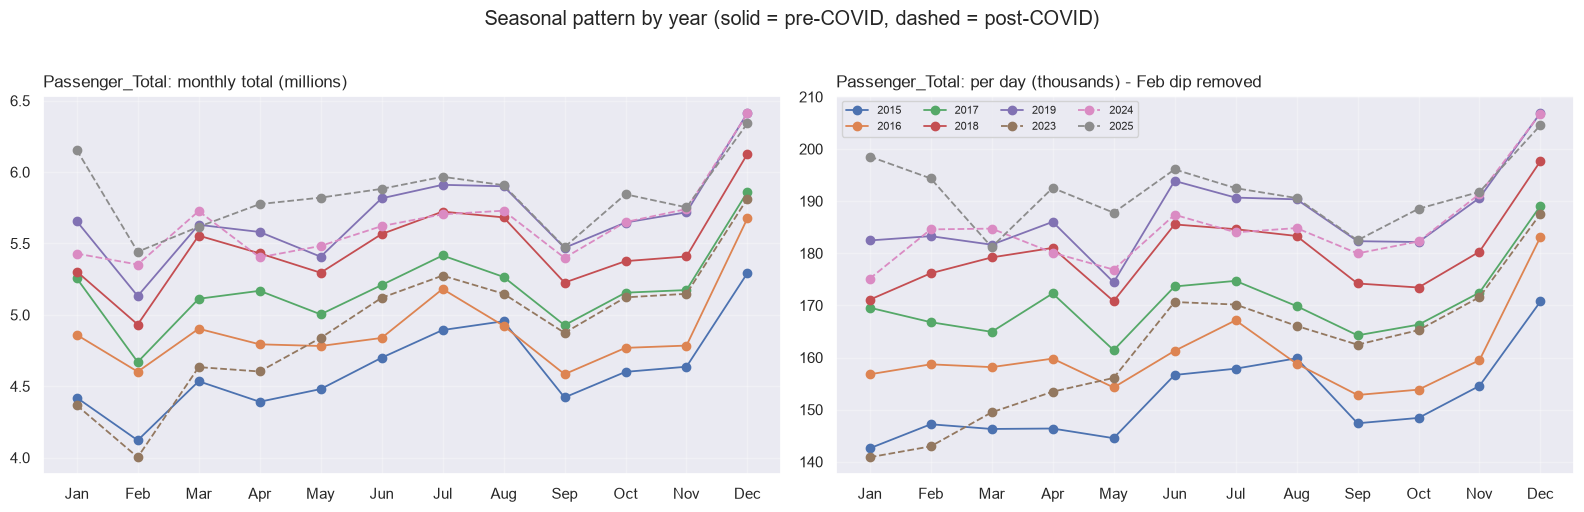

In [22]:
col = "Passenger_Total"       # try "Cargo_Total" or "Aircraft_Total" too
normal_years = [2015, 2016, 2017, 2018, 2019, 2023, 2024, 2025]   # skip COVID years

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), sharex=True)
for yr in normal_years:
    s = d.loc[str(yr), col]
    per_day = s / s.index.days_in_month          # Feb has 28/29 days, others 30/31
    style = dict(marker="o", lw=1.3, ls="-" if yr < 2020 else "--", label=str(yr))
    ax1.plot(s.index.month, s.values / 1e6, **style)
    ax2.plot(s.index.month, per_day.values / 1e3, **style)

ax1.set_title(f"{col}: monthly total (millions)", loc="left")
ax2.set_title(f"{col}: per day (thousands) - Feb dip removed", loc="left")
for ax in (ax1, ax2):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS)
    ax.grid(alpha=0.3)
ax2.legend(ncol=4, fontsize=8)
fig.suptitle("Seasonal pattern by year (solid = pre-COVID, dashed = post-COVID)", y=1.02)
fig.tight_layout()
plt.show()

Part 3: Seasonal-Trend decomposition using LOESS

STL separates each series into a long-term trend, a repeating yearly pattern and residual noise, so the seasonal pattern can be studied without the trend and unusual months can be identified as large residuals.

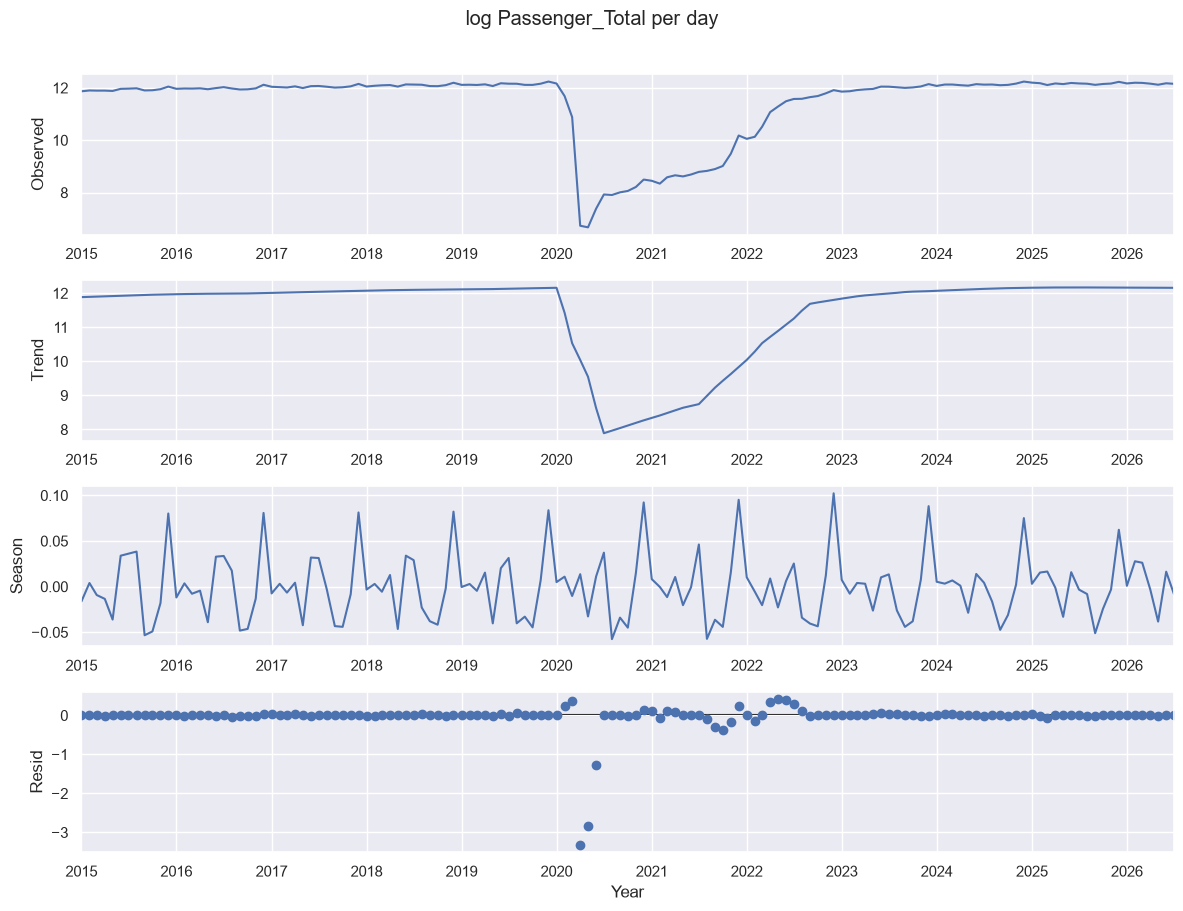

In [23]:
from statsmodels.tsa.seasonal import STL
import matplotlib.dates as mdates
col = "Passenger_Total"
y = d[col].asfreq("MS")
y = y / y.index.days_in_month          # per day: removes the February dip
y = np.log(y)                          # seasonal effect becomes % instead of absolute

res = STL(y, period=12, trend=13, robust=True).fit()   # trend=13 lets the trend follow COVID
fig = res.plot()
fig.set_size_inches(12, 9)
fig.suptitle(f"log {col} per day", y=1.01)

fig.axes[0].set_ylabel("Observed")              # y-axis label for first plot

for ax in fig.axes:                             # year ticks on every plot
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, rotation=0)

fig.axes[-1].set_xlabel("Year")
fig.tight_layout()
plt.show()

Figure Z. STL decomposition of daily passenger traffic (log scale), 2015–2026
The STL decomposition separates daily passenger traffic into trend, seasonal and residual components. The trend rose steadily from 2015 to 2019 (a log value of about 12, roughly 160,000–200,000 passengers a day), collapsed in early 2020, and climbed back to pre-pandemic levels by 2023–2024, where it has since remained stable. The seasonal component shows a consistent yearly pattern: December is the strongest month, about 8–10% above trend, while the weakest months are about 5% below trend. This pattern persisted throughout the period, though the December peak has been slightly smaller in the most recent years. The residuals are close to zero in normal years, so trend and seasonality explain passenger traffic well. The main exceptions are April–June 2020, when traffic fell far faster than the smoothed trend could follow (residuals of up to −3.3 on the log scale, meaning traffic was about 96% below the expected level), and smaller deviations during the 2021–2022 reopening.


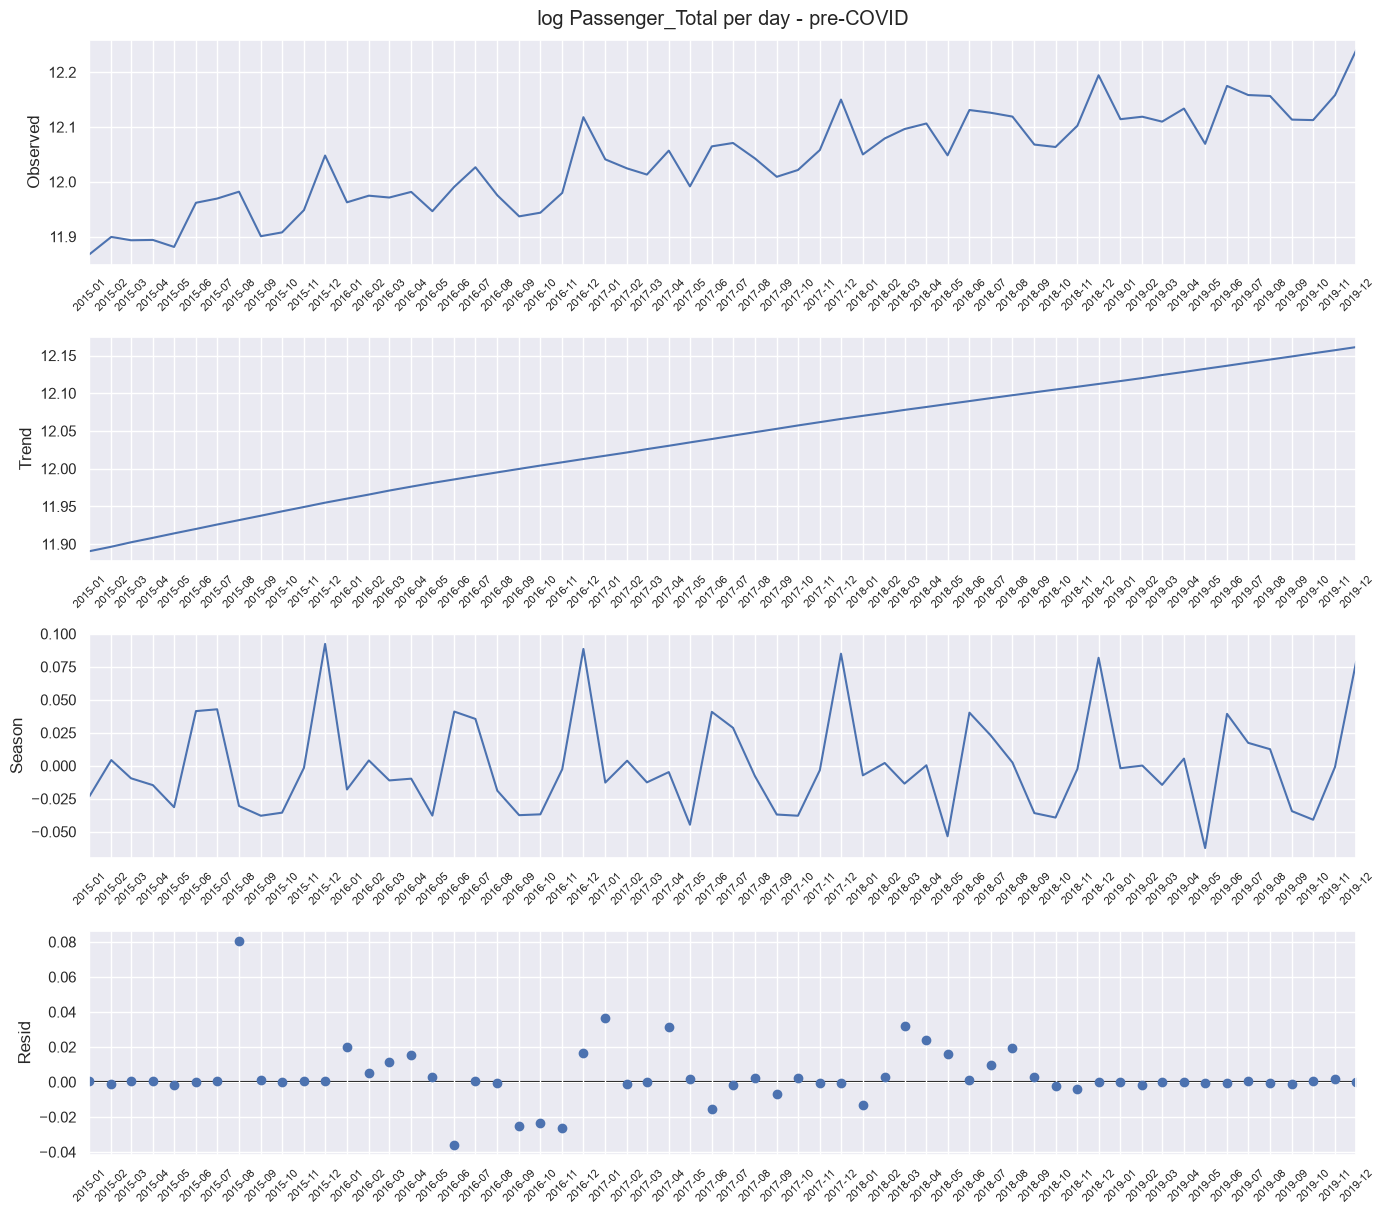

In [24]:
#decomposition for pre-COVID
y_pre = d.loc[:"2019-12", col].asfreq("MS")
y_pre = np.log(y_pre / y_pre.index.days_in_month)     # log per day, to match the title

res = STL(y_pre, period=12, robust=True).fit()
fig = res.plot()
fig.set_size_inches(12, 9)
fig.axes[0].set_ylabel("Observed")
fig.axes[0].set_title("")                             # remove the duplicate "Passenger_Total" label
fig.tight_layout()

for ax in fig.axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator())             # a tick every month
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45, labelsize=8)

fig.set_size_inches(14, 12)      # wider and taller to fit 43 monthly labels
fig.tight_layout()

# centre the main title over the plots
pos = fig.axes[0].get_position()
fig.suptitle(f"log {col} per day - pre-COVID", x=(pos.x0 + pos.x1) / 2, y=1.01)
plt.show()

The pre-pandemic STL decomposition shows steady growth of about 5–6% a year in daily passenger traffic between 2015 and 2019. Traffic follows a stable seasonal pattern, peaking in December at about 8–10% above trend, with a smaller June–July peak and lows in May, September and October of about 4–6% below trend. The residuals are mostly within ±4%, showing that trend and seasonality explain most of the variation. The main exception is August 2015, about 8% above expectations.

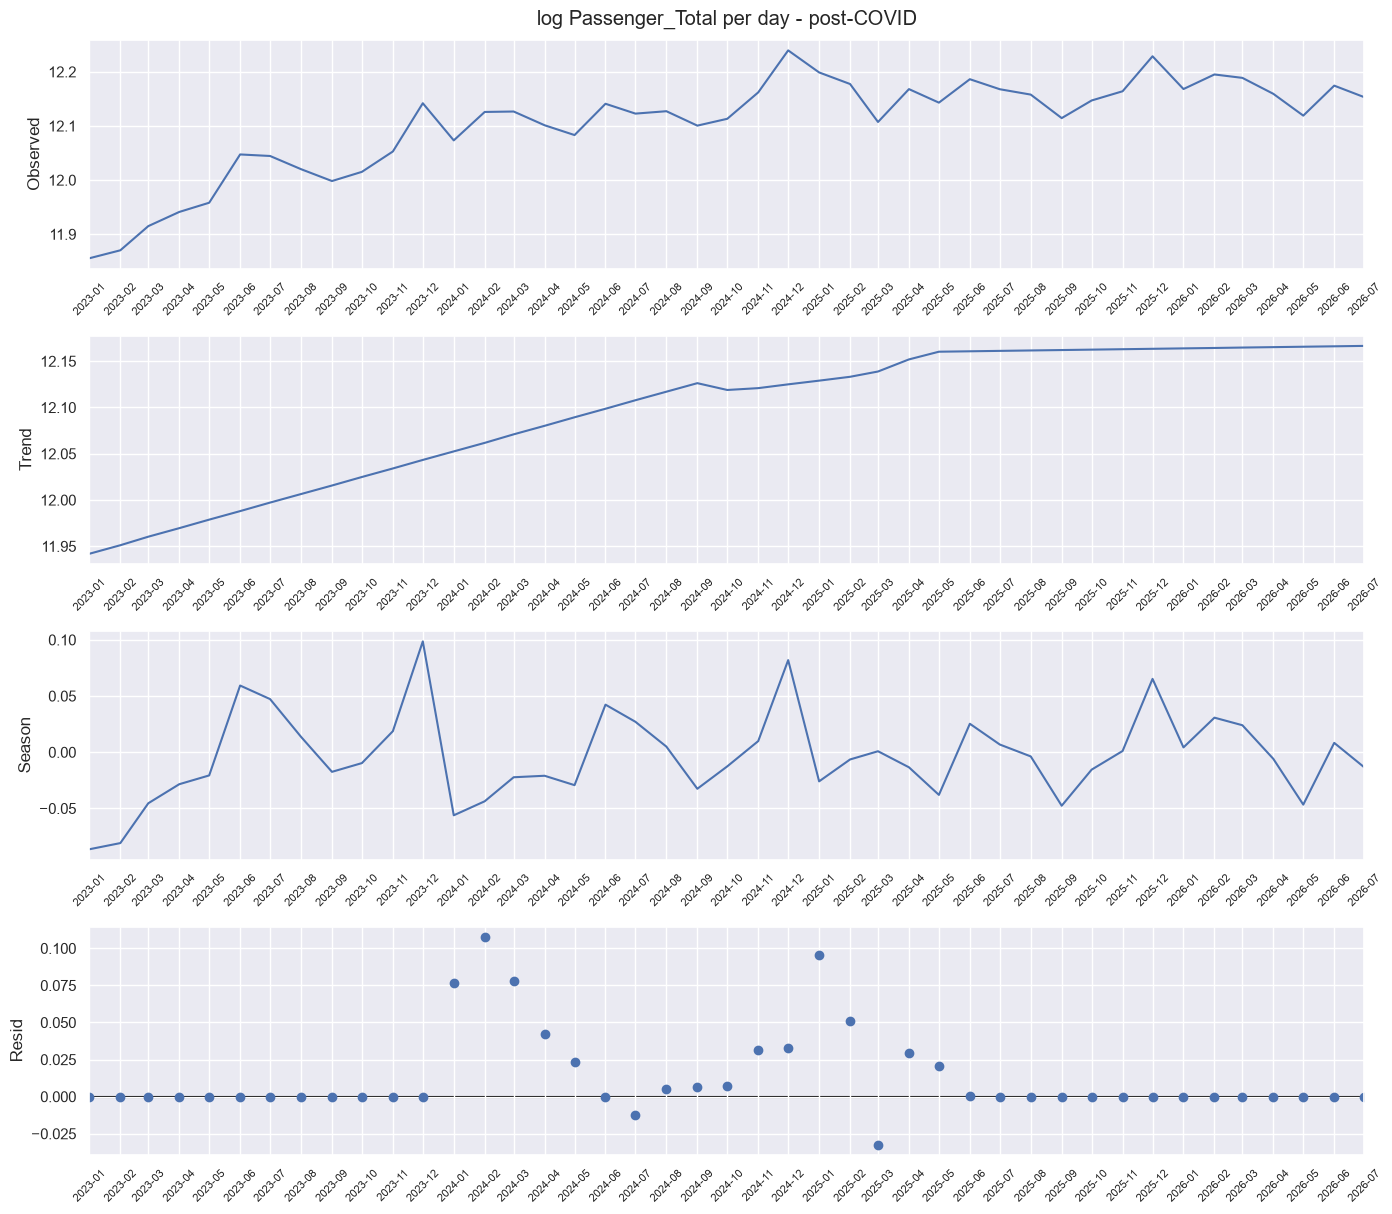

In [25]:
y_pre = d.loc["2023-01":, col].asfreq("MS")
y_pre = np.log(y_pre / y_pre.index.days_in_month)     # log per day, to match the title

res = STL(y_pre, period=12, robust=True).fit()
fig = res.plot()
fig.set_size_inches(12, 9)
fig.axes[0].set_ylabel("Observed")
fig.axes[0].set_title("")                             # remove the duplicate "Passenger_Total" label
fig.tight_layout()

for ax in fig.axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator())             # a tick every month
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45, labelsize=8)

fig.set_size_inches(14, 12)      # wider and taller to fit 43 monthly labels
fig.tight_layout()

# centre the main title over the plots
pos = fig.axes[0].get_position()
fig.suptitle(f"log {col} per day - post-COVID", x=(pos.x0 + pos.x1) / 2, y=1.01)
plt.show()

A separate decomposition for 2023–2026 shows that the passenger trend returned to its 2019 level by mid-2025 and has since levelled off, compared with growth of about 5–6% a year before the pandemic. The familiar seasonal pattern persists, with peaks in December and June and lows in May and September. With only three and a half years of data, however, the seasonal and residual estimates for this period are less reliable than those for 2015–2019, and the early-2023 values still reflect the end of the pandemic recovery.

Part 5: Clustering

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


         pax_per_flight  cargo_per_flight  transit_share  export_import  \
cluster                                                                   
0                172.38              5.69           0.01           0.85   
1                  6.52             24.80           0.08           0.80   
2                 13.31             22.46           0.00           0.90   
3                 33.17             17.37           0.01           0.94   

         arr_dep_pax_ratio  pct_2019_pax  
cluster                                   
0                     1.02         89.89  
1                     0.33          0.44  
2                     0.55          1.26  
3                     0.95          6.08  
cluster
0    2015-01 to 2026-07 (115 months)
1      2020-04 to 2020-04 (1 months)
2      2020-05 to 2020-10 (6 months)
3     2020-11 to 2022-03 (17 months)
dtype: str

Out-of-bag accuracy: 0.99


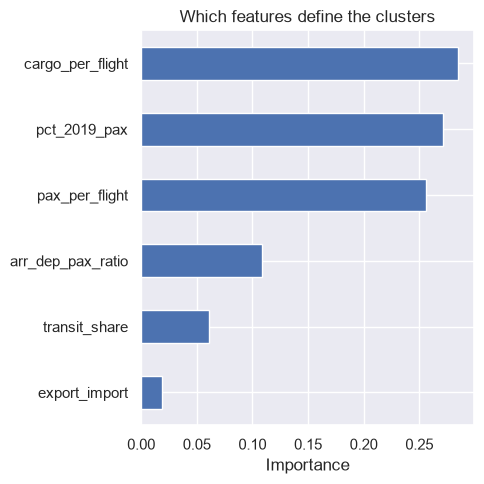

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier

# 1. date index
d = df.copy()
if "Month" in d.columns:
    d["Month"] = pd.to_datetime(d["Month"])
    d = d.set_index("Month").sort_index()

# 2. ratio features
feat = pd.DataFrame({
    "pax_per_flight":    d["Passenger_Total"] / d["Aircraft_Total"],
    "cargo_per_flight":  d["Cargo_Total"] / d["Aircraft_Total"],
    "transit_share":     d["Passenger_Transit"] / d["Passenger_Total"],
    "export_import":     d["Cargo_Total_Export"] / d["Cargo_Total_Import"],
    "arr_dep_pax_ratio": d["Passenger_Arrival"] / d["Passenger_Departures"],
    "pct_2019_pax":      d["Passenger_Total"] / d.loc["2019", "Passenger_Total"].mean() * 100,
}, index=d.index)

# 3. K-Means clustering of months
X = feat.copy()
X_scaled = StandardScaler().fit_transform(X)
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_scaled)
labels = km.labels_
feat["cluster"] = labels

print(feat.groupby("cluster").mean().round(2))
print(feat.groupby("cluster").apply(
    lambda g: f"{g.index.min():%Y-%m} to {g.index.max():%Y-%m} ({len(g)} months)"))

# 4. random forest to explain the clusters
rf = RandomForestClassifier(n_estimators=500, random_state=42, oob_score=True)
rf.fit(X, labels)
print(f"\nOut-of-bag accuracy: {rf.oob_score_:.2f}")

pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh(
    title="Which features define the clusters")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

Summary statistics were used to screen the candidate features. All seven features were complete (139 months) but on very different scales: for example, passengers per flight averaged about 147, while the export/import ratio averaged 0.86. All features were therefore standardised before clustering, so that each counts equally. The statistics also show two limitations. First, the export/import ratio varied very little (coefficient of variation 0.06), apart from a single outlier in March 2022, so it contributes little information. Second, transit share and cargo per flight contain extreme pandemic values; April 2020’s transit share, for instance, is about 10 standard deviations above the mean. All features were kept in their original form so that the clustering reflects the full range of the data, including the pandemic. Because of these extremes, K-Means mainly separates COVID-affected months from normal months, as the following results show.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


         pax_per_flight  cargo_per_flight  transit_share  export_import  \
cluster                                                                   
0               182.602             5.269          0.009          0.874   
1               164.204             5.482          0.012          0.840   
2               175.927             5.638          0.009          0.835   

         arr_dep_pax_ratio  
cluster                     
0                    1.038  
1                    1.017  
2                    0.997  
col_0   0   1  2
row_0           
2015    0  10  2
2016    0   4  8
2017    0   6  6
2018    1   8  3
2019    6   3  3
2020    1   0  0
2023   10   0  2
2024    7   0  5
2025    5   0  7
2026    2   0  5

Out-of-bag accuracy: 0.93


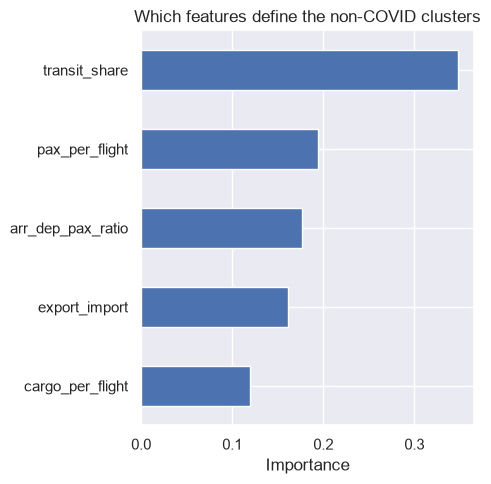

In [27]:
normal = (feat.index < "2020-02-01") | (feat.index >= "2023-01-01")
X = feat.loc[normal].drop(columns=["cluster", "pct_2019_pax"])

X_scaled = StandardScaler().fit_transform(X)
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X_scaled)
labels_n = km.labels_

print(X.assign(cluster=labels_n).groupby("cluster").mean().round(3))
print(pd.crosstab(X.index.year, labels_n))      # which years fall in which cluster

rf = RandomForestClassifier(n_estimators=500, random_state=42, oob_score=True)
rf.fit(X, labels_n)
print(f"\nOut-of-bag accuracy: {rf.oob_score_:.2f}")
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh(
    title="Which features define the non-COVID clusters")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

When COVID months are excluded, K-Means finds only weak structure (silhouette 0.21), and the clusters mainly reflect gradual change over time rather than distinct regimes. Feature importance is spread across several features. Transit share is the strongest separator (higher in 2015–2018, at about 1.2% of passengers, than in recent years, at about 0.9%), followed by passengers per flight, which rose from about 164 to 183. This suggests that normal-period operations evolved gradually, with fuller flights and a smaller transit share, rather than switching between distinct operating states

In [28]:
#K-means clustering - feature screening

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

EXCLUDE_COVID = False               # True = cluster only normal months (2015-Jan 2020, 2023-)
K = None                            # None = pick k with the best silhouette; or set e.g. K = 3

# ratio features: remove the scale effect so clusters reflect behaviour, not just size
feat = pd.DataFrame({
    "pax_per_flight":   d["Passenger_Total"] / d["Aircraft_Total"],
    "cargo_per_flight": d["Cargo_Total"] / d["Aircraft_Total"],
    "transit_share":    d["Passenger_Transit"] / d["Passenger_Total"] * 100,
    "export_import":    d["Cargo_Total_Export"] / d["Cargo_Total_Import"],
    "pct_2019_pax":     d["Passenger_Total"] / d.loc["2019", "Passenger_Total"].mean() * 100,
    "pct_2019_cargo":   d["Cargo_Total"] / d.loc["2019", "Cargo_Total"].mean() * 100,
    "pct_2019_mail": d["AirMail_Total"] / d.loc["2019", "AirMail_Total"].mean() * 100,
}, index=d.index)

if EXCLUDE_COVID:
    feat = feat[(feat.index < "2020-02-01") | (feat.index >= "2023-01-01")]

X = StandardScaler().fit_transform(feat)      # K-Means needs features on the same scale
feat.describe().round(2)

,pax_per_flight,cargo_per_flight,transit_share,export_import,pct_2019_pax,pct_2019_cargo,pct_2019_mail
count,139.00,139.00,139.00,139.00,139.00,139.00,139.00
mean,147.29,7.98,0.96,0.86,75.17,96.68,63.48
std,57.22,5.27,0.69,0.05,35.12,11.26,28.95
min,5.48,4.57,0.02,0.78,0.43,57.10,19.10
25%,156.04,5.31,0.81,0.83,71.39,90.50,38.43
50%,169.08,5.62,0.92,0.85,90.19,97.28,61.55
75%,182.28,6.17,1.06,0.89,99.09,105.54,87.76
max,193.36,24.80,8.23,1.25,112.73,114.75,148.15


Summary statistics were used to screen the candidate features. All features were complete (139 months) but on very different scales, so they were standardised before clustering. The export/import ratio was excluded because it varied very little (coefficient of variation 0.06) apart from a single outlier in March 2022. Transit share and cargo per flight contained extreme pandemic values (up to 10 standard deviations from the mean), so they were log-transformed to stop single months from forming their own clusters.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

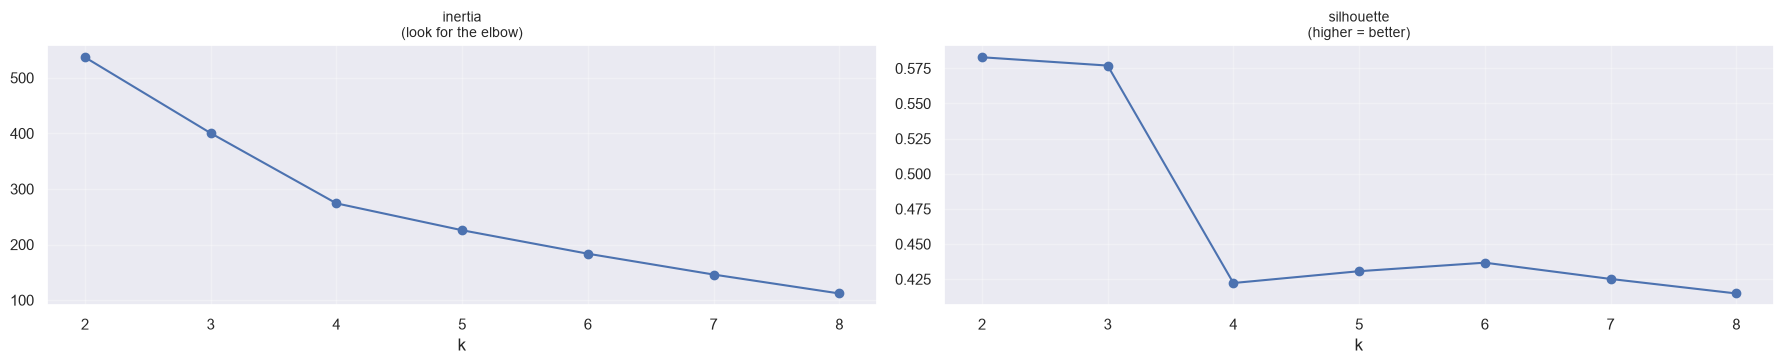

,inertia,silhouette
k,,
2,536.981,0.583
3,400.451,0.577
4,274.091,0.422
5,225.714,0.431
6,183.481,0.437
7,146.004,0.425
8,111.944,0.415


In [29]:
#K-means clustering - visualisation to help select k

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({"k": k,
                 "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_)})

scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(18, 3.8))
for ax, (c, hint) in zip(axes, [("inertia", "look for the elbow"),
                                ("silhouette", "higher = better")]):
                               
    ax.plot(scores.index, scores[c], marker="o")
    ax.set_title(f"{c}\n({hint})", fontsize=10)
    ax.set_xlabel("k"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

scores.round(3)

In [30]:
#check k=2 model
K = None

if K is None:
    K = int(scores["silhouette"].idxmax())
print(f"Using k = {K}")

km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
feat["cluster"] = km.labels_

profile = feat.groupby("cluster").mean().round(2)
profile["n_months"] = feat["cluster"].value_counts().sort_index()
profile["first"] = feat.groupby("cluster").apply(lambda g: g.index.min().strftime("%Y-%m"))
profile["last"]  = feat.groupby("cluster").apply(lambda g: g.index.max().strftime("%Y-%m"))
profile

Using k = 2


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,pax_per_flight,cargo_per_flight,transit_share,export_import,pct_2019_pax,pct_2019_cargo,pct_2019_mail,n_months,first,last
cluster,,,,,,,,,,
0,27.09,18.95,0.86,0.92,4.64,86.79,55.34,24,2020-04,2022-03
1,172.38,5.69,0.98,0.85,89.89,98.74,65.18,115,2015-01,2026-07


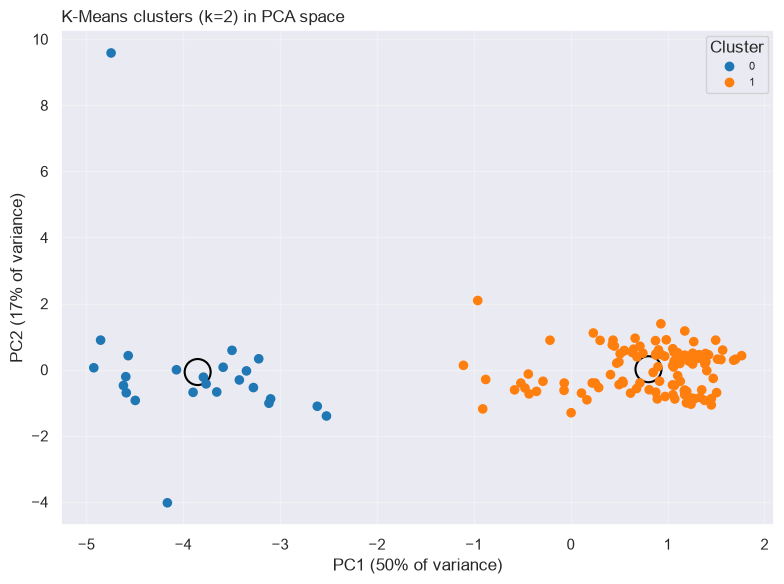

In [31]:
#k=2 plot
pca = PCA(n_components=2).fit(X)
pc = pca.transform(X)
centres = pca.transform(km.cluster_centers_)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(centres[:, 0], centres[:, 1], marker="o", s=350, facecolors="none",
           edgecolors="black", lw=1.5, label="cluster centre", zorder=1)
sc = ax.scatter(pc[:, 0], pc[:, 1], c=feat["cluster"], cmap="tab10",
                vmin=0, vmax=9, s=35, zorder=2)
ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title(f"K-Means clusters (k={K}) in PCA space", loc="left")
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

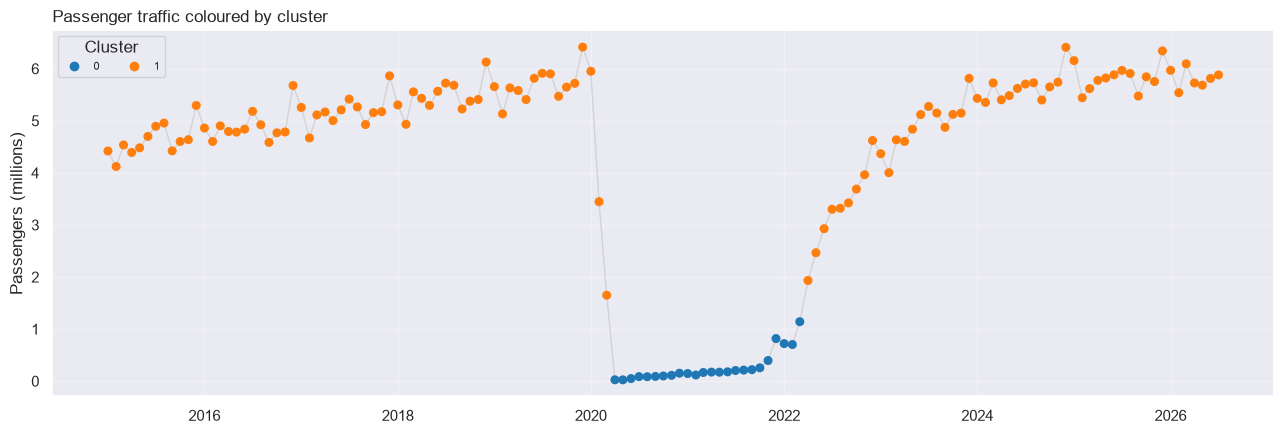

In [32]:
#k=2 plot 
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(d.index, d["Passenger_Total"] / 1e6, color="lightgrey", lw=1, zorder=1)
sc = ax.scatter(feat.index, d.loc[feat.index, "Passenger_Total"] / 1e6,
                c=feat["cluster"], cmap="tab10", vmin=0, vmax=9, s=30, zorder=2)
ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8, ncol=K)
ax.set_ylabel("Passengers (millions)")
ax.set_title("Passenger traffic coloured by cluster", loc="left")
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

In [33]:
#Use K-Means on scaled indicators (passenger volume, YoY growth, transit ratio, cargo share) to find groups such as peak, regular, off-peak and disrupted months

from statsmodels.tsa.seasonal import STL
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

if "Passenger_Total_Per_Day" not in d.columns:
    d["Passenger_Total_Per_Day"] = d["Passenger_Total"] / d.index.days_in_month
pax = d["Passenger_Total_Per_Day"]

def pct_vs_trend(series):
    """% above/below the STL trend: positive = busier than normal for that time."""
    y = np.log(series).asfreq("MS")
    trend = STL(y, period=12, trend=13, robust=True).fit().trend
    return (np.exp(y - trend) - 1) * 100

feat = pd.DataFrame({
    "log_pax_per_day":  np.log(pax),                              # passenger volume
    "yoy_growth":       np.log(pax).diff(12).clip(-3, 3),         # log YoY (0.1 = +10%)
    "transit_ratio":    d["Passenger_Transit"] / d["Passenger_Total"] * 100,
    "cargo_per_flight": d["Cargo_Total"] / d["Aircraft_Total"],   # cargo share of operations
    "pax_vs_trend":     pct_vs_trend(pax),                        # seasonal busyness
}).dropna()            # 2015 is dropped: YoY needs 12 months of history
feat.describe().round(2)

,log_pax_per_day,yoy_growth,transit_ratio,cargo_per_flight,pax_vs_trend
count,127.00,127.00,127.00,127.00,127.00
mean,11.38,0.13,0.94,8.23,0.24
std,1.42,1.26,0.72,5.45,18.04
min,6.67,-3.00,0.02,4.57,-96.34
25%,11.69,0.03,0.80,5.35,-3.00
50%,12.05,0.07,0.90,5.68,0.22
75%,12.13,0.26,1.05,6.68,3.09
max,12.24,2.80,8.23,24.80,51.26


Summary statistics show that all regime features are dominated by extreme pandemic values: for example, passenger volume fell to about 790 a day and transit share rose to 8% in April 2020. In normal months, by contrast, passenger traffic varied by only about ±3% around its trend. A two-stage approach was therefore used: the first K-Means step separated disrupted months, and the second step clustered only the normal months on deviation from trend, so that the small seasonal differences were not swamped by pandemic extremes.

In [34]:
#finding the disrupted months
s1_cols = ["log_pax_per_day", "yoy_growth", "transit_ratio", "cargo_per_flight"]
X1 = StandardScaler().fit_transform(feat[s1_cols])
km1 = KMeans(n_clusters=2, n_init=20, random_state=42).fit(X1)
print(f"Stage 1 silhouette: {silhouette_score(X1, km1.labels_):.2f}")

low_cluster = feat.groupby(km1.labels_)["log_pax_per_day"].mean().idxmin()
core = feat.index[km1.labels_ == low_cluster]
print(f"K-Means disrupted core: {core.min():%Y-%m} to {core.max():%Y-%m} ({len(core)} months)")

# K-Means finds the core collapse (Apr 2020 - Nov 2021); widen to the full COVID window
# so the falling and recovery months don't distort the seasonal clustering in stage 2
DISRUPTED = (feat.index >= "2020-02-01") & (feat.index <= "2022-12-31")
feat["regime"] = np.where(DISRUPTED, "Disrupted", "")

Stage 1 silhouette: 0.74
K-Means disrupted core: 2020-04 to 2021-11 (20 months)


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [35]:
#look for peak, regular, offpeak
normal = feat[~DISRUPTED].copy()
X2 = StandardScaler().fit_transform(normal[["pax_vs_trend"]])

for k in range(2, 6):
    lab = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X2)
    print(f"k={k}: silhouette {silhouette_score(X2, lab):.2f}")

km2 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X2)
normal["c"] = km2.labels_

# name clusters by how busy they are (cluster numbers are arbitrary)
order = normal.groupby("c")["pax_vs_trend"].mean().sort_values().index
names = dict(zip(order, ["Off-peak", "Regular", "Peak"]))
normal["regime"] = normal["c"].map(names)
feat.loc[normal.index, "regime"] = normal["regime"]

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
summary = feat.groupby("regime").agg(
    months=("pax_vs_trend", "size"),
    pax_vs_trend_pct=("pax_vs_trend", "mean"),
    pax_per_day=("log_pax_per_day", lambda s: np.exp(s).mean()),
    transit_ratio=("transit_ratio", "mean"),
    cargo_per_flight=("cargo_per_flight", "mean"),
).round(1).loc[["Peak", "Regular", "Off-peak", "Disrupted"]]
display(summary)
pd.crosstab(feat["regime"], feat.index.strftime("%b"))[MONTHS]

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


k=2: silhouette 0.56
k=3: silhouette 0.62
k=4: silhouette 0.63


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


k=5: silhouette 0.58


,months,pax_vs_trend_pct,pax_per_day,transit_ratio,cargo_per_flight
regime,,,,,
Peak,11,7.6,190453.3,0.9,5.3
Regular,57,0.9,177851.6,0.9,5.5
Off-peak,24,-3.8,172119.4,1.0,5.7
Disrupted,35,-0.4,38567.0,0.9,15.4


col_0,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
regime,,,,,,,,,,,,
Disrupted,2,3,3,3,3,3,3,3,3,3,3,3
Off-peak,1,0,1,0,7,0,0,0,7,7,1,0
Peak,0,1,0,0,0,2,1,0,0,0,0,7
Regular,8,7,7,8,1,6,7,7,0,0,6,0


The two-stage clustering identified four traffic regimes. Disrupted months (February 2020 – December 2022, 35 months) averaged about 39,000 passengers a day, with cargo-heavy operations (about 15 cargo units per flight compared with about 5.5 normally). Among normal months, December was a peak month in every year, at about 8% above trend, while May, September and October were consistently off-peak, at about 4% below trend. Most other months were regular. Transit share and cargo per flight were almost identical across the three normal regimes, so seasonal differences reflect passenger volume rather than changes in how the airport operates. 

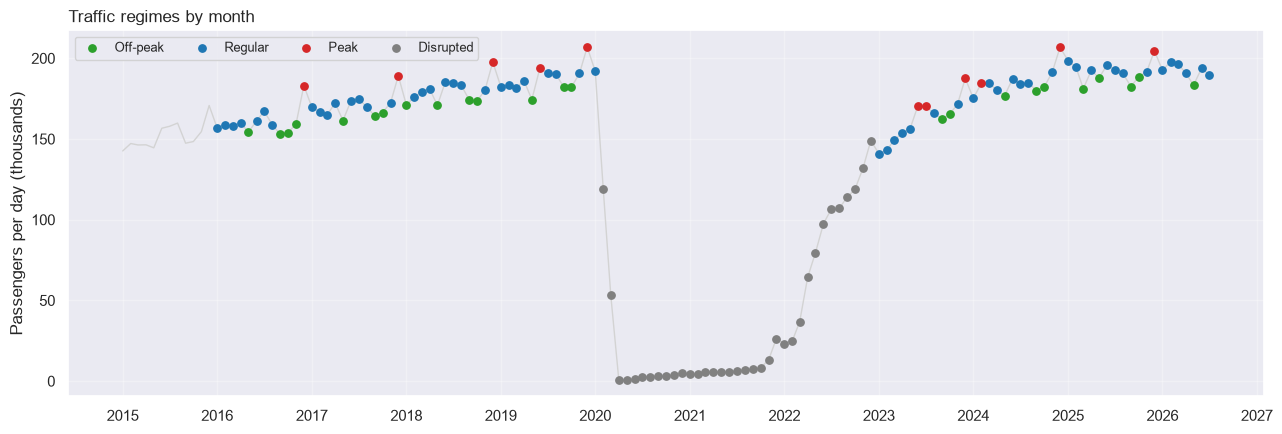

In [36]:
import matplotlib.dates as mdates

colors = {"Off-peak": "tab:green", "Regular": "tab:blue", "Peak": "tab:red", "Disrupted": "grey"}

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(pax.index, pax / 1e3, color="lightgrey", lw=1, zorder=1)
for r, c in colors.items():
    m = feat["regime"] == r
    ax.scatter(feat.index[m], pax[feat.index[m]] / 1e3, color=c, s=28, label=r, zorder=2)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))

ax.set_ylabel("Passengers per day (thousands)")
ax.set_title("Traffic regimes by month", loc="left")
ax.legend(ncol=4, fontsize=9)
ax.grid(alpha=0.3, which="major")
fig.tight_layout()
plt.show()

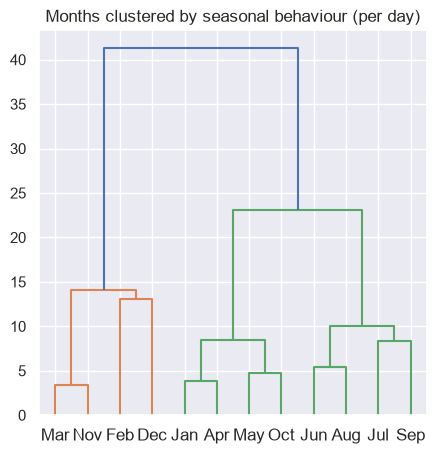

     Passenger_Total_Per_Day  Aircraft_Total_Per_Day  Cargo_Total_Per_Day  \
Feb                      0.6                     2.0                 -6.6   
Mar                      0.2                     0.2                  3.8   
Nov                     -0.3                     0.4                  6.3   
Dec                      8.2                     2.4                  2.1   
May                     -3.6                    -1.8                 -0.0   
Oct                     -3.9                    -1.3                  1.7   
Jan                     -0.2                     1.8                 -3.0   
Apr                      0.2                     0.2                 -0.6   
Aug                     -0.7                    -0.8                 -1.6   
Jul                      1.9                    -0.7                 -0.8   
Jun                      2.4                    -0.0                 -1.4   
Sep                     -4.4                    -1.7                  3.0   

In [37]:
from statsmodels.tsa.seasonal import STL
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
series = ["Passenger_Total_Per_Day", "Aircraft_Total_Per_Day", "Cargo_Total_Per_Day", "Passenger_Transit_Per_Day"]
normal = (d.index < "2020-02-01") | (d.index >= "2023-01-01")

# average seasonal effect (%) per calendar month for each series, normal years only
prof = {}
for c in series:
    y = np.log(d[c]).asfreq("MS")                    # already per day, so no division
    s = STL(y, period=12, trend=13, robust=True).fit().seasonal[normal]
    prof[c] = ((np.exp(s) - 1) * 100).groupby(s.index.month).mean()
season = pd.DataFrame(prof)
season.index = MONTHS

Z = linkage(season, method="ward")
dendrogram(Z, labels=MONTHS)
plt.title("Months clustered by seasonal behaviour (per day)")
plt.show()

season["cluster"] = fcluster(Z, t=3, criterion="maxclust")
print(season.round(1).sort_values("cluster"))

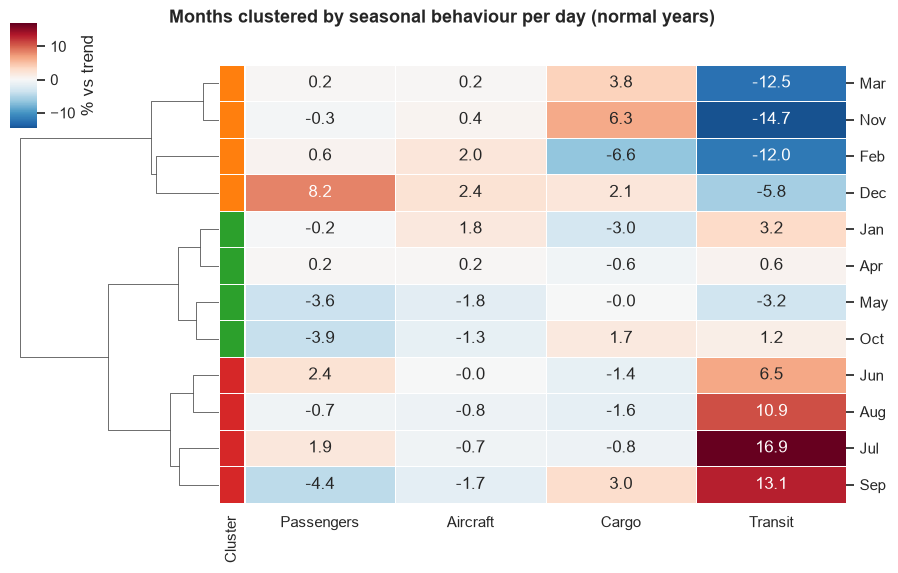

In [38]:
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster

cols = ["Passenger_Total_Per_Day", "Aircraft_Total_Per_Day", "Cargo_Total_Per_Day", "Passenger_Transit_Per_Day"]   # define first

labels = fcluster(linkage(season[cols], method="ward"), t=3, criterion="maxclust")
row_colors = pd.Series(labels, index=season.index).map(
    {1: "tab:orange", 2: "tab:green", 3: "tab:red"}).rename("Cluster")

g = sns.clustermap(
    season[cols],
    method="ward",
    col_cluster=False,
    cmap="RdBu_r", center=0,
    annot=True, fmt=".1f",
    linewidths=0.5,
    figsize=(9, 7),
    dendrogram_ratio=(0.25, 0.05),
    cbar_pos=(0.02, 0.85, 0.03, 0.15),
    cbar_kws={"label": "% vs trend"},
    row_colors=row_colors,
)

g.ax_heatmap.set_xticklabels(["Passengers", "Aircraft", "Cargo", "Transit"], rotation=0)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
g.figure.suptitle("Months clustered by seasonal behaviour per day (normal years)",
                  fontsize=13, fontweight="bold", y=1.02)
plt.show()

As a supporting method, agglomerative hierarchical clustering (Ward linkage) grouped the 12 calendar months by their average seasonal effect on passengers, aircraft, cargo and transit per day in normal years. It produced three groups. February, March, November and December share below-trend transit (−6% to −15%), although they differ on other measures: December is the passenger peak (+8%), while February is the weakest cargo month (−7%). January, April, May and October stay close to trend across all series. June to September form a mid-year transit peak (+7% to +17%). Because transit has the largest seasonal swings, it largely drives this grouping. The result therefore differs from the K-Means regimes, which are based on passenger volume and identify December as peak and May, September and October as off-peak. Taken together, the two methods show that passenger and transit traffic follow different seasonal calendars.

Notes: Cluster (tree colour)	Months	What the heatmap shows
Orange:	Mar, Nov, Feb, Dec:	Dark blue in the transit column (−6 to −15%). Cargo is red in Nov and Mar (+4 to +6%) but blue in Feb (−7%). Dec is the passenger peak (+8%).
Green:	Jan, Apr, May, Oct:	Pale across the board, close to trend: the “average” months. May and Oct are mild passenger lows (−4%).
Red:	Jun, Jul, Aug, Sep:	Dark red in the transit column (+7 to +17%), the mid-year transit peak.

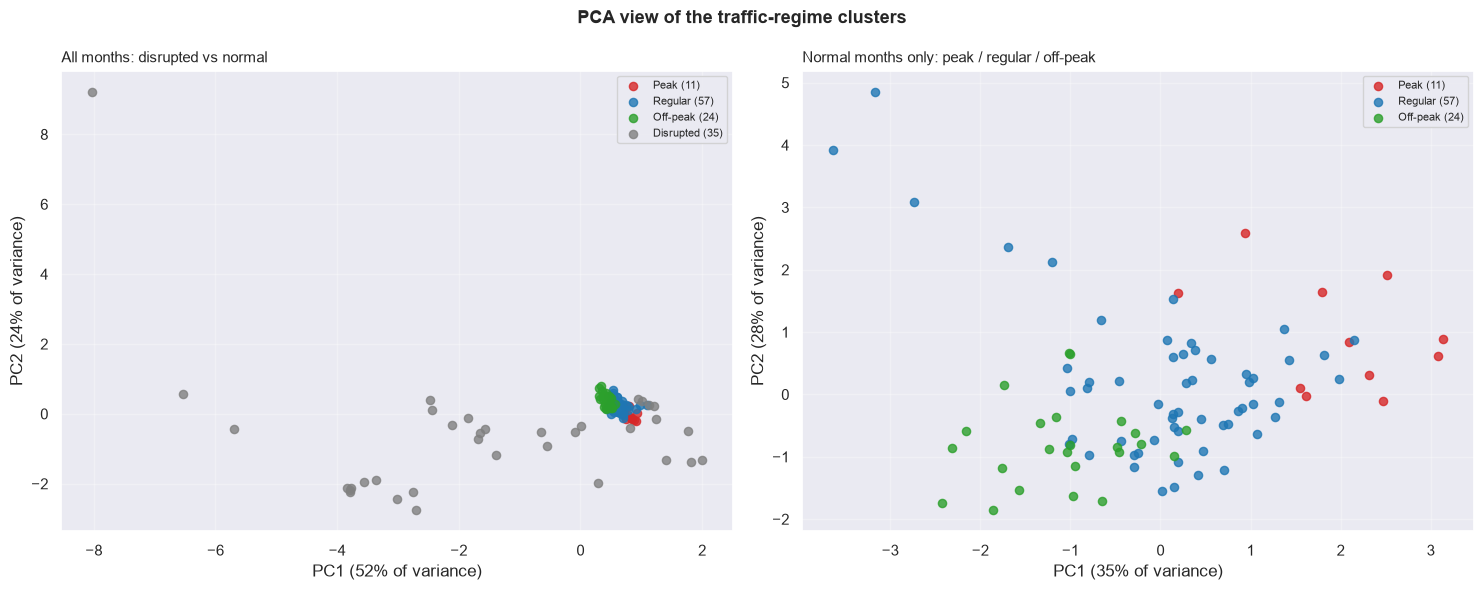

Loadings - all months:
                    PC1   PC2
log_pax_per_day   0.58  0.21
yoy_growth        0.42  0.07
transit_ratio    -0.12  0.80
cargo_per_flight -0.57 -0.25
pax_vs_trend      0.40 -0.49

Loadings - normal months:
                    PC1   PC2
log_pax_per_day   0.63 -0.34
yoy_growth       -0.34  0.66
transit_ratio    -0.32 -0.29
cargo_per_flight -0.32 -0.48
pax_vs_trend      0.54  0.36


In [39]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

feat_cols = ["log_pax_per_day", "yoy_growth", "transit_ratio", "cargo_per_flight", "pax_vs_trend"]
colors = {"Peak": "tab:red", "Regular": "tab:blue", "Off-peak": "tab:green", "Disrupted": "grey"}

def pca_plot(data, title, ax):
    Xs = StandardScaler().fit_transform(data[feat_cols])
    pca = PCA(n_components=2).fit(Xs)
    pc = pca.transform(Xs)
    for r, c in colors.items():
        m = (data["regime"] == r).values
        if m.any():
            ax.scatter(pc[m, 0], pc[m, 1], color=c, s=35, alpha=0.8, label=f"{r} ({m.sum()})")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    # loadings: how much each feature contributes to each component
    return pd.DataFrame(pca.components_.T, index=feat_cols, columns=["PC1", "PC2"]).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
load_all  = pca_plot(feat, "All months: disrupted vs normal", ax1)
load_norm = pca_plot(feat[feat["regime"] != "Disrupted"],
                     "Normal months only: peak / regular / off-peak", ax2)
fig.suptitle("PCA view of the traffic-regime clusters", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

print("Loadings - all months:\n", load_all)
print("\nLoadings - normal months:\n", load_norm)

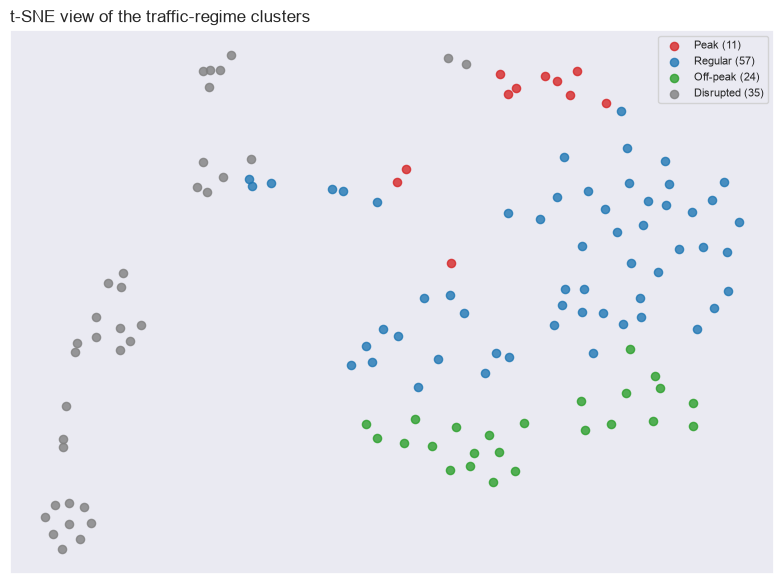

In [40]:
from sklearn.manifold import TSNE

Xs = StandardScaler().fit_transform(feat[feat_cols])
emb = TSNE(n_components=2, perplexity=20, random_state=42, init="pca").fit_transform(Xs)

fig, ax = plt.subplots(figsize=(8, 6))
for r, c in colors.items():
    m = (feat["regime"] == r).values
    ax.scatter(emb[m, 0], emb[m, 1], color=c, s=35, alpha=0.8, label=f"{r} ({m.sum()})")
ax.set_title("t-SNE view of the traffic-regime clusters", loc="left")
ax.set_xticks([]); ax.set_yticks([])          # t-SNE axes have no meaning
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

PCA confirms that disrupted months are clearly separated from normal months along the first principal component (52% of variance), which contrasts passenger volume with cargo per flight. Within normal months, peak and off-peak months lie at opposite ends of the first component, although they overlap with regular months, because the seasonal regimes were defined by deviation from trend alone. A t-SNE projection shows the four regimes as distinct groups.